### Per-nucleus calcium transients in hiPSC-vCMs after CARBONITE: cardiomyocytes only
#### Lavie Ngo
#### This notebook: The same plots as `5-plot-calcium.ipynb`, restricted to cTnT+ nuclei (cardiomyocytes, from `3b-classify-ctnt.py`): CM counts per well, example traces, per-well mean traces, heatmaps, spatial maps, peak dF/F0 distributions, and per-well summaries comparing maintenance vs. Feyen media at 1 and 2 weeks.

#### Experiment info:
- Differentiated vCMs (D0: 08/31/26) were replated on D18 (09/18/26) into two 96-well plates and cultured in maintenance media until D25 (09/25/26). On D25, wells were moved to their assigned media:
    - Wells B02-B09: Maintenance media (control)
    - Wells C02-C09: Feyen maturation media (treatment)
- Plate 1: 1 week in assigned media; CARBONITE (Rhod-2) on 10/02/26, then fixed.
- Plate 2: 2 weeks in assigned media; CARBONITE (Rhod-2) on 10/09/26, then fixed.
- Spontaneous beating (not paced). 1000 frames at 101.73 Hz (9.83 ms/frame, from the TIFF timestamps) = 9.82 s per movie.

#### Pipeline (scripts in this folder):
- **1** `1-cellpose-nuclei.py`: Cellpose nuclei on DAPI (w1).
- **2** `2-align-mi.py`: cTnT (w2) aligned to Rhod-2 frame 0 by mutual information.
- **3** `3-extract-nuclear-transients.py`: nuclei mapped onto the movie with the 7-of-9 core rule; mean Rhod-2 per nucleus per frame.
- **3b** `3b-classify-ctnt.py`: **CM filter.** Median cTnT (w2, full resolution) in a 6 px (~4 um) perinuclear ring, divided by the well's background (mode of the cTnT histogram). **cTnT+ if ratio >= 2.0.** That cut sits in the valley between the background peak (ratio ~1) and the cTnT+ mode (~3-8), pooled over all 31 wells (KDE minimum 1.49; Plate 1 2.14, Plate 2 1.45). Distributions: `Calcium/qc/ctnt_threshold.png`; overlays: `Calcium/<plate>/ctnt_qc/<well>.png`.
- **4** `4-extract-calcium-features.py` + `calcium.py`: dF/F0 = (F - F0)/F0, F0 = 10th percentile; beats detected at 5x each nucleus's own noise.

#### Caveats (read before interpreting):
- The cTnT call is made on the fixed plate, after the movie. At 10X, a non-CM nucleus lying on or tightly against CM cytoplasm can read cTnT+, mostly in the dense Plate 2 clusters. The QC overlays show how often.
- Beats are slow (~0.2-0.3 Hz), so each nucleus has only 1-3 transients per movie; beat rate per nucleus is quantised (2 beats = 0.20 Hz, 3 = 0.31 Hz).
- **Excluded:** Plate 1 C07 (alignment failed; see `experiment.yaml`). **Flagged (hollow points):** Plate 2 C05/C06 (hair/debris in the fixed images; the C05 fiber is also in the Rhod-2 movie).
- One well = one replicate; per-well summaries use the median over that well's nuclei. No statistics yet.

In [1]:
# Reusable plotting functions
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import calcium

CALCIUM_DIR = Path("../../Calcium")
FIG_DIR = CALCIUM_DIR / "figures"
PREFIX = "CM_"      # every figure and table from this notebook

PLATES = {
    "plate1": "Plate 1: 1 week",
    "plate2": "Plate 2: 2 weeks",
}
CONDITIONS = ["Maintenance media", "Feyen maturation media"]
CONDITION_COLORS = {"Maintenance media": "#4C72B0", "Feyen maturation media": "#DD8452"}
FLAGGED_WELLS = {("plate2", "C05"): "debris", ("plate2", "C06"): "debris"}
MIN_PEAK_DFF = 0.2      # "active" = beating and peak dF/F0 >= this (notebook-5 placeholder)

# dF/F0 settings: calcium.py defaults (Alex's), so plots match the pipeline
DFF_SETTINGS = {"f0_pct": calcium.F0_PCT, "smooth": calcium.SMOOTH, "trim": calcium.TRIM}

# Per-well summary metrics: column -> (axis label, scale)
METRICS = {
    "pct_beating": ("CMs counted (%)", 1),
    "beat_rate": ("Beat rate (Hz)", 1),
    "amplitude": ("Amplitude (dF/F0)", 1),
    "peak_dff": ("Peak dF/F0", 1),
    "time_to_peak": ("Time to peak (ms)", 1000),
    "duration_50": ("Duration at 50% (ms)", 1000),
    "duration_90": ("Duration at 90% (ms)", 1000),
    "tau_decay": ("Decay tau (ms)", 1000),
}
CM_METRICS = {
    "n_cm": ("CM nuclei in movie", 1),
    "pct_cm": ("CMs, % of nuclei in movie", 1),
    "n_cm_stain": ("CM nuclei, whole stain field", 1),
    "pct_cm_stain": ("CMs, % of nuclei, whole stain field", 1),
}


def load_features(plates=PLATES):
    """One row per nucleus in the movie (step-4 output), with the step-3b cTnT call joined on
    Well + ObjectNumber (ObjectNumber is only unique within a well)."""
    frames = []
    for plate in plates:
        f = pd.read_csv(CALCIUM_DIR / plate / "calcium_features.csv")
        c = pd.read_csv(CALCIUM_DIR / plate / "ctnt_classification.csv",
                        usecols=["Well", "ObjectNumber", "ctnt_ratio", "cTnT_pos", "ring_shared"])
        frames.append(f.merge(c, on=["Well", "ObjectNumber"], how="left", validate="1:1"))
    features = pd.concat(frames, ignore_index=True)
    if features.cTnT_pos.isna().any():
        raise ValueError("Some nuclei have no cTnT call; re-run 3b-classify-ctnt.py.")
    features["cTnT_pos"] = features.cTnT_pos.astype(bool)
    return features


def load_classification(plates=PLATES):
    """Every segmented nucleus in the stain image (inside the movie or not), step-3b output."""
    return pd.concat([pd.read_csv(CALCIUM_DIR / plate / "ctnt_classification.csv") for plate in plates],
                     ignore_index=True)


def load_traces(plate, well):
    """Raw traces for one well -> (ObjectNumber array, F matrix [nuclei x frames], dt)."""
    tr = pd.read_parquet(CALCIUM_DIR / plate / "nuclear_traces.parquet", filters=[("Well", "==", well)])
    if tr.empty:
        raise ValueError(f"No traces for {plate} {well} (excluded or not extracted).")
    return tr.ObjectNumber.to_numpy(), np.stack(tr.CalciumTrace.to_numpy()), float(tr.FrameInterval_s.iloc[0])


def dff_matrix(F, settings=DFF_SETTINGS):
    """dF/F0 for every row of F with calcium.dff(), so plots use the pipeline's exact maths."""
    return np.stack([calcium.dff(row, settings["f0_pct"], settings["smooth"], settings["trim"]) for row in F])


def time_axis(n_frames, dt, trim=DFF_SETTINGS["trim"]):
    return (np.arange(n_frames) + trim) * dt


def well_dff(plate, well, features):
    """dF/F0 of every nucleus in one well, with the matching feature rows (same order) and time."""
    objects, F, dt = load_traces(plate, well)
    f = features.query("Plate == @plate and Well == @well").set_index("ObjectNumber").loc[objects]
    d = dff_matrix(F)
    return d, f, time_axis(d.shape[1], dt)


def _save(fig, name):
    if name is None:
        return
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{PREFIX}{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Exported: {path}")


def well_label(plate, well):
    flag = FLAGGED_WELLS.get((plate, well))
    return f"{well} ({flag})" if flag else well


def summarize_cm_counts(features, classification):
    """One row per well: CM count and fraction, inside the movie and over the whole stain field."""
    movie = features.groupby(["Plate", "Well", "Condition"]).agg(
        n_nuclei=("cTnT_pos", "size"), n_cm=("cTnT_pos", "sum")).reset_index()
    stain = classification.groupby(["Plate", "Well"]).agg(
        n_nuclei_stain=("cTnT_pos", "size"), n_cm_stain=("cTnT_pos", "sum")).reset_index()
    s = movie.merge(stain, on=["Plate", "Well"], how="left")
    s["pct_cm"] = 100 * s.n_cm / s.n_nuclei
    s["pct_cm_stain"] = 100 * s.n_cm_stain / s.n_nuclei_stain
    s["flagged"] = [FLAGGED_WELLS.get((p, w), "") for p, w in zip(s.Plate, s.Well)]
    return s


def plot_example_traces(plate, wells, features, n_top=3, n_random=5, seed=0, export_name=None):
    """Per well, CMs only: the n_top highest-peak CMs (red) and n_random random beating CMs (grey),
    with the mean of all CMs (black). Rows = wells."""
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(len(wells), 1, figsize=(10, 2.2 * len(wells)), sharex=True, squeeze=False)
    for ax, well in zip(axes[:, 0], wells):
        d, f, t = well_dff(plate, well, features)
        cm = f.cTnT_pos.to_numpy()
        d, f = d[cm], f[cm]
        beating = np.flatnonzero(f.beating.to_numpy())
        top = np.argsort(f.peak_dff.to_numpy())[-n_top:]
        rand = rng.choice(beating, size=min(n_random, beating.size), replace=False)
        for i in rand:
            ax.plot(t, d[i], color="0.6", lw=0.6)
        for i in top:
            ax.plot(t, d[i], color="C3", lw=0.8)
        ax.plot(t, d.mean(axis=0), color="k", lw=1.5)
        ax.set_title(f"{PLATES[plate]} | {well_label(plate, well)} | {f.Condition.iloc[0]} | {len(f)} CMs", fontsize=9)
        ax.set_ylabel("dF/F0")
    axes[-1, 0].set_xlabel("Time (s)")
    fig.suptitle(f"CMs only: red = {n_top} highest-peak CMs, grey = {n_random} random 'beating' CMs, black = mean of all CMs",
                 fontsize=9)
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def plot_trace_heatmap(plate, well, features, n_show=300, vmax=0.5, export_name=None):
    """dF/F0 heatmap of the n_show highest-peak CMs (top row = highest), with the CM mean below."""
    d, f, t = well_dff(plate, well, features)
    cm = f.cTnT_pos.to_numpy()
    d, f = d[cm], f[cm]
    order = np.argsort(f.peak_dff.to_numpy())[::-1][:n_show]
    fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [4, 1]})
    im = ax0.imshow(d[order], aspect="auto", cmap="magma", vmin=0, vmax=vmax,
                    extent=(t[0], t[-1], len(order), 0), interpolation="nearest")
    ax0.set_ylabel(f"CMs (top {len(order)} of {len(f)} by peak)")
    ax0.set_title(f"{PLATES[plate]} | {well_label(plate, well)} | {f.Condition.iloc[0]}", fontsize=10)
    fig.colorbar(im, ax=[ax0, ax1], label="dF/F0", shrink=0.8)
    ax1.plot(t, d.mean(axis=0), color="k", lw=1)
    ax1.set_ylabel("mean, all CMs")
    ax1.set_xlabel("Time (s)")
    _save(fig, export_name)
    plt.show()
    return fig


def plot_plate_mean_traces(plate, features, top_frac=0.1, export_name=None):
    """Plate layout (rows = conditions, columns = wells): mean dF/F0 of all CMs (black), of the top
    `top_frac` of CMs by peak dF/F0 (red), and of the non-CM nuclei (grey) for contrast."""
    wells = sorted(features.query("Plate == @plate").Well.unique())
    rows = {"B": 0, "C": 1}
    columns = sorted({int(w[1:]) for w in wells})
    fig, axes = plt.subplots(2, len(columns), figsize=(2.2 * len(columns), 4.4), sharex=True, sharey=True, squeeze=False)
    for ax in axes.ravel():
        ax.set_axis_off()
    for well in wells:
        ax = axes[rows[well[0]], columns.index(int(well[1:]))]
        ax.set_axis_on()
        d, f, t = well_dff(plate, well, features)
        cm = f.cTnT_pos.to_numpy()
        peak = d[cm].max(axis=1)
        top = peak >= np.quantile(peak, 1 - top_frac)
        ax.plot(t, d[~cm].mean(axis=0), color="0.65", lw=0.8)
        ax.plot(t, d[cm][top].mean(axis=0), color="C3", lw=0.8)
        ax.plot(t, d[cm].mean(axis=0), color="k", lw=0.8)
        ax.set_title(f"{well_label(plate, well)} ({cm.sum()} CMs)", fontsize=8)
    for condition_row, condition in enumerate(CONDITIONS):
        axes[condition_row, 0].set_ylabel(f"{condition}\ndF/F0", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Time (s)", fontsize=8)
    fig.suptitle(f"{PLATES[plate]}: mean dF/F0 of CMs (black), top {top_frac:.0%} of CMs by peak (red), non-CMs (grey)",
                 fontsize=10)
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def plot_spatial_map(plate, well, features, metric="peak_dff", vmax=0.5, export_name=None):
    """CMs at their calcium-movie position, coloured by a per-nucleus metric; non-CMs as grey dots."""
    f = features.query("Plate == @plate and Well == @well")
    cm, non = f[f.cTnT_pos], f[~f.cTnT_pos]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(non.live_x, non.live_y, s=1, color="0.85")
    sc = ax.scatter(cm.live_x, cm.live_y, c=cm[metric], s=4, cmap="viridis", vmin=0, vmax=vmax)
    ax.set_xlim(0, 682)
    ax.set_ylim(682, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{PLATES[plate]} | {well_label(plate, well)} | {f.Condition.iloc[0]} | {len(cm)} CMs (grey = non-CM)",
                 fontsize=10)
    fig.colorbar(sc, ax=ax, label=metric, shrink=0.8)
    _save(fig, export_name)
    plt.show()
    return fig


def plot_peak_distributions(features, min_peak_dff=None, export_name=None):
    """Peak dF/F0 per 'beating' nucleus (>= 2 peaks), by plate and condition (log x).
    Solid = CMs, dashed = non-CMs, so the effect of the filter on the beat criterion is visible."""
    bins = np.logspace(-2, 1, 80)
    fig, axes = plt.subplots(1, len(PLATES), figsize=(5 * len(PLATES), 3.5), sharey=True)
    for ax, (plate, plate_name) in zip(np.atleast_1d(axes), PLATES.items()):
        for condition in CONDITIONS:
            for is_cm, ls in [(True, "-"), (False, "--")]:
                values = features.query("Plate == @plate and Condition == @condition and beating "
                                        "and cTnT_pos == @is_cm").peak_dff
                ax.hist(values.clip(lower=bins[0]), bins=bins, histtype="step", lw=1.5 if is_cm else 1,
                        ls=ls, density=True, color=CONDITION_COLORS[condition],
                        label=f"{condition}, {'CM' if is_cm else 'non-CM'} (n={len(values)})")
        if min_peak_dff is not None:
            ax.axvline(min_peak_dff, color="k", lw=0.8, ls=":")
        ax.set_xscale("log")
        ax.set_xlabel("Peak dF/F0 per 'beating' nucleus")
        ax.set_title(plate_name)
        ax.legend(fontsize=7)
    np.atleast_1d(axes)[0].set_ylabel("Density")
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def summarize_wells(features, min_peak_dff=None):
    """One row per well, CMs only. pct_beating = counted CMs / all CMs in the movie; the other
    metrics are medians over the counted CMs: beating, and optionally also peak_dff >= min_peak_dff."""
    rows = []
    cms = features[features.cTnT_pos]
    for (plate, well, condition), f in cms.groupby(["Plate", "Well", "Condition"]):
        active = f[f.beating]
        if min_peak_dff is not None:
            active = active[active.peak_dff >= min_peak_dff]
        row = {"Plate": plate, "Well": well, "Condition": condition, "n_cm": len(f),
               "n_active": len(active), "pct_beating": 100 * len(active) / len(f),
               "flagged": FLAGGED_WELLS.get((plate, well), "")}
        for metric in METRICS:
            if metric != "pct_beating":
                row[metric] = active[metric].median()
        rows.append(row)
    return pd.DataFrame(rows)


def plot_well_metrics(summary, metrics=METRICS, title=None, export_name=None):
    """One panel per metric: one point per well, grouped by plate and condition, median bar.
    Flagged wells are hollow."""
    labels = {**METRICS, **CM_METRICS}
    metrics = {m: labels[m] for m in metrics}
    ncols = 4
    nrows = int(np.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3 * nrows), squeeze=False)
    rng = np.random.default_rng(0)
    positions = {(plate, condition): i + 3 * p for p, plate in enumerate(PLATES)
                 for i, condition in enumerate(CONDITIONS)}
    for ax, (metric, (label, scale)) in zip(axes.ravel(), metrics.items()):
        for (plate, condition), x in positions.items():
            s = summary.query("Plate == @plate and Condition == @condition")
            y = s[metric] * scale
            jitter = x + rng.uniform(-0.15, 0.15, len(s))
            color = CONDITION_COLORS[condition]
            flagged = s.flagged.astype(bool).to_numpy()
            ax.scatter(jitter[~flagged], y[~flagged], s=22, color=color, zorder=3)
            ax.scatter(jitter[flagged], y[flagged], s=22, facecolor="none", edgecolor=color, zorder=3)
            ax.hlines(np.nanmedian(y), x - 0.3, x + 0.3, color="k", lw=1.5)
        ax.set_xticks([0.5 + 3 * p for p in range(len(PLATES))], list(PLATES.values()), fontsize=8)
        ax.set_title(label, fontsize=9)
    for ax in axes.ravel()[len(metrics):]:
        ax.set_axis_off()
    handles = [plt.Line2D([], [], marker="o", ls="", color=CONDITION_COLORS[c], label=c) for c in CONDITIONS]
    handles.append(plt.Line2D([], [], marker="o", ls="", mfc="none", mec="0.3", label="flagged (debris)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(title or "Per-well medians (one point per well; bar = median of wells)", fontsize=10)
    fig.tight_layout(rect=(0, 0.04, 1, 1 if nrows > 1 else 0.93))
    _save(fig, export_name)
    plt.show()
    return fig


def group_medians(summary, metrics):
    """Median of per-well values for each plate x condition (the numbers quoted in CLAUDE.md)."""
    m = summary.groupby(["Plate", "Condition"])[list(metrics)].median()
    for metric in metrics:
        if metric in METRICS and METRICS[metric][1] == 1000:
            m[metric] *= 1000
    return m.reindex(CONDITIONS, level="Condition")


# --- Aligned transient overlays (after Alex's display_cal_transients / return_average_cal_trace
# --- / plot_cal_by_condition in clark-deep-phenotyping/iPSC-CM/6-plot_features.py)
ALIGN_PRE = 50          # frames before the transient start (Alex's), ~0.49 s at 101.73 Hz
ALIGN_POST = 350        # frames after (Alex's time_range), ~3.44 s
ALIGN_FRAC = 0.1        # align on the 10%-of-amplitude crossing of the rise
ALIGN_N = 50            # transients sampled per well (Alex's)
ALIGN_SEED = 0
ALIGN_MIN_WELL = 5      # wells with fewer transients are drawn but left out of the condition means
ALIGN_MIN_REL = 0.5     # a transient counts only if its amplitude is >= this x the nucleus's largest


def first_complete_transient(d, dt, pre=ALIGN_PRE, post=ALIGN_POST, frac=ALIGN_FRAC, min_rel=ALIGN_MIN_REL):
    """Start index of the first full-size transient whose whole window fits in the trace, or None.

    Peaks are found exactly as in calcium.features(). For each peak, the baseline is the
    minimum since the previous peak (as in calcium.kinetics()), and the start is the first
    frame of the rise above baseline + frac x amplitude. "Full-size" = amplitude >= min_rel x
    the nucleus's largest transient: the 5x-noise detector also picks up small blips, and
    without this rule the first "transient" of many active CMs is a blip before the real one."""
    pk = calcium.detect(d, dt, calcium.peak_height(d, calcium.SNR_K, calcium.FLOOR),
                        calcium.MIN_SEP, calcium.WIDTH)
    events = []
    for i, p in enumerate(pk):
        lo = pk[i - 1] if i > 0 else 0
        pre_seg = d[lo:p + 1]
        if len(pre_seg) < 3:
            continue
        base = pre_seg.min()
        amp = d[p] - base
        below = np.flatnonzero(pre_seg <= base + frac * amp)
        if amp > 0 and below.size:
            events.append((lo + below[-1] + 1, amp))
    if not events:
        return None
    biggest = max(amp for _, amp in events)
    for start, amp in events:
        if amp >= min_rel * biggest and start - pre >= 0 and start + post <= len(d):
            return start
    return None


def aligned_transients(plate, well, features, n_max=ALIGN_N, seed=ALIGN_SEED, min_peak_dff=MIN_PEAK_DFF):
    """Aligned dF/F0 windows for one well: active CMs only (beating, peak dF/F0 >= min_peak_dff),
    first complete transient of each, then a seeded random sample of up to n_max.
    Returns dict(t, traces [n x frames], n_active, n_complete)."""
    d, f, t = well_dff(plate, well, features)
    dt = t[1] - t[0]
    active = (f.cTnT_pos & f.beating & (f.peak_dff >= min_peak_dff)).to_numpy()
    windows = []
    for row in d[active]:
        s = first_complete_transient(row, dt)
        if s is not None:
            windows.append(row[s - ALIGN_PRE:s + ALIGN_POST])
    windows = np.array(windows).reshape(-1, ALIGN_PRE + ALIGN_POST)
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(windows), size=min(n_max, len(windows)), replace=False)
    return {"t": (np.arange(-ALIGN_PRE, ALIGN_POST)) * dt, "traces": windows[np.sort(pick)],
            "n_active": int(active.sum()), "n_complete": len(windows)}


def collect_aligned(features, plates=PLATES):
    """aligned_transients() for every well, keyed by (plate, well)."""
    return {(plate, well): aligned_transients(plate, well, features)
            for plate in plates for well in sorted(features.query("Plate == @plate").Well.unique())}


def plot_aligned_transients(plate, aligned, export_name=None):
    """Plate layout (rows = conditions, columns = wells), shared axes: sampled aligned transients
    (thin grey), their mean (thick black), dashed line at the transient start (t = 0)."""
    wells = sorted(w for p, w in aligned if p == plate)
    rows = {"B": 0, "C": 1}
    columns = sorted({int(w[1:]) for w in wells})
    fig, axes = plt.subplots(2, len(columns), figsize=(2.2 * len(columns), 4.6), sharex=True, sharey=True,
                             squeeze=False)
    for ax in axes.ravel():
        ax.set_axis_off()
    for well in wells:
        a = aligned[(plate, well)]
        ax = axes[rows[well[0]], columns.index(int(well[1:]))]
        ax.set_axis_on()
        for tr in a["traces"]:
            ax.plot(a["t"], tr, color="0.6", lw=0.4, alpha=0.4)
        if len(a["traces"]):
            ax.plot(a["t"], a["traces"].mean(axis=0), color="k", lw=1.8)
        ax.axvline(0, color="C3", ls="--", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_title(f"{well_label(plate, well)}\nn = {len(a['traces'])} of {a['n_complete']}", fontsize=8,
                     color="C3" if FLAGGED_WELLS.get((plate, well)) else "k")
    for condition_row, condition in enumerate(CONDITIONS):
        axes[condition_row, 0].set_ylabel(f"{condition}\ndF/F0", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Time from start (s)", fontsize=8)
    fig.suptitle(f"{PLATES[plate]}: first complete full-size transient of each active CM, aligned at "
                 f"{ALIGN_FRAC:.0%} of the rise (grey = up to {ALIGN_N} per well, black = mean; "
                 f"n = shown of complete)", fontsize=10)
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig


def condition_means(aligned, plate, condition, min_well=ALIGN_MIN_WELL, normalize=False):
    """Per-well mean traces for one plate x condition (wells with >= min_well transients).
    normalize=True scales each well mean to baseline 0 (pre-start median), peak 1 (max within 1 s of t = 0)."""
    rows = {"Maintenance media": "B", "Feyen maturation media": "C"}
    means, wells = [], []
    for (p, well), a in aligned.items():
        if p != plate or well[0] != rows[condition] or len(a["traces"]) < min_well:
            continue
        m = a["traces"].mean(axis=0)
        if normalize:
            m = m - np.median(m[:ALIGN_PRE])
            m = m / m[ALIGN_PRE:ALIGN_PRE + int(round(1 / (a["t"][1] - a["t"][0])))].max()
        means.append(m)
        wells.append(well)
    return np.array(means), wells


def plot_aligned_means(aligned, min_well=ALIGN_MIN_WELL, export_name=None):
    """Per plate: mean of per-well mean traces for each condition, band = +/- 1 SD across wells.
    Top row in dF/F0; bottom row with each well mean scaled to peak 1, to compare shape alone."""
    fig, axes = plt.subplots(2, len(PLATES), figsize=(5.5 * len(PLATES), 6.5), sharex=True, squeeze=False)
    t = next(iter(aligned.values()))["t"]
    for col, (plate, plate_name) in enumerate(PLATES.items()):
        for row, normalize in enumerate([False, True]):
            ax = axes[row, col]
            for condition in CONDITIONS:
                means, wells = condition_means(aligned, plate, condition, min_well, normalize)
                n_tr = sum(len(aligned[(plate, w)]["traces"]) for w in wells)
                color = CONDITION_COLORS[condition]
                label = f"{condition}: {len(wells)} wells, {n_tr} transients"
                if not len(means):
                    ax.plot([], [], color=color, label=f"{condition}: no well with >= {min_well}")
                    continue
                mu = means.mean(axis=0)
                ax.plot(t, mu, color=color, lw=2, label=label)
                if len(means) > 1:
                    sd = means.std(axis=0, ddof=1)
                    ax.fill_between(t, mu - sd, mu + sd, color=color, alpha=0.2, lw=0)
            ax.axvline(0, color="0.3", ls="--", lw=0.8)
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_ylabel("dF/F0 (scaled, peak = 1)" if normalize else "dF/F0")
            if row == 0:
                ax.set_title(plate_name)
            ax.legend(fontsize=8, frameon=False)
        axes[-1, col].set_xlabel("Time from start (s)")
    fig.suptitle(f"Aligned transients, CMs only: mean of per-well means (band = +/- 1 SD across wells; "
                 f"wells with >= {min_well} transients)", fontsize=10)
    fig.tight_layout()
    _save(fig, export_name)
    plt.show()
    return fig

**What the aligned overlays show (exploratory, 2026-10-29):**
- **Rise shape is similar across conditions.** Scaled to peak = 1, maintenance and Feyen rise together and peak ~0.3-0.4 s after the start, on both plates.
- **Plate 2: Feyen transients return to baseline, maintenance ones mostly do not.** Feyen falls back to ~0.05-0.07 dF/F0 by ~1.5 s. Maintenance stays near 0.2 for the rest of the 3.4 s window, with a wide band across wells. The fast maintenance wells (B04, B05, B07 at ~0.7-0.8 Hz) carry the next beat inside the window, and several wells show transients riding on a raised level.
- **That is at odds with the duration table** (Plate 2 D90: Feyen 1175 ms vs. maintenance 467 ms). `calcium.kinetics()` keeps a transient's durations only if it decays to 10% of amplitude before the next peak, so the durations describe the subset of transients that do recover. Maintenance transients that never recover drop out, which makes maintenance look shorter. Treat the "Feyen transients are longer" reading with care until this is resolved, for example by measuring durations in the aligned windows.
- **Plate 1:** maintenance has clear transients (mean peak ~0.33). Feyen has only C03 with enough transients (small, ~0.1). B02's "transients" are mostly a slow decline already underway at frame 0 (see its mean trace above), and it dominates the wide band in the scaled Plate 1 panel.

In [2]:
# Improve inline figure quality
%config InlineBackend.figure_format = "retina"
plt.rcParams["figure.dpi"] = 100

In [3]:
# Load per-nucleus features (both plates) with the cTnT call
features = load_features()
classification = load_classification()
print(f"{len(features)} nuclei in the movies, {features.cTnT_pos.sum()} cTnT+ (CM), "
      f"{features.groupby('Plate').Well.nunique().to_dict()} wells")
features.groupby(["Plate", "Condition", "cTnT_pos"]).agg(
    nuclei=("beating", "size"), pct_beating=("beating", "mean"), median_peak_dff=("peak_dff", "median")
).round(3)

77621 nuclei in the movies, 37211 cTnT+ (CM), {'plate1': 15, 'plate2': 16} wells


nuclei  pct_beating  median_peak_dff
Plate  Condition              cTnT_pos                                      
plate1 Feyen maturation media False      12745        0.495            0.055
                              True        4225        0.586            0.058
       Maintenance media      False      12667        0.575            0.066
                              True        4469        0.790            0.145
plate2 Feyen maturation media False       7006        0.467            0.049
                              True       15370        0.863            0.207
       Maintenance media      False       7992        0.559            0.064
                              True       13147        0.891            0.280

#### CM count and fraction per well
`n_cm` / `pct_cm` count the nuclei inside the calcium movie (the ones with traces). `n_cm_stain` / `pct_cm_stain` count every segmented nucleus in the stain image, including the ~17% strip outside the movie.

Exported: ../../Calcium/figures/CM_well-cm-counts.png


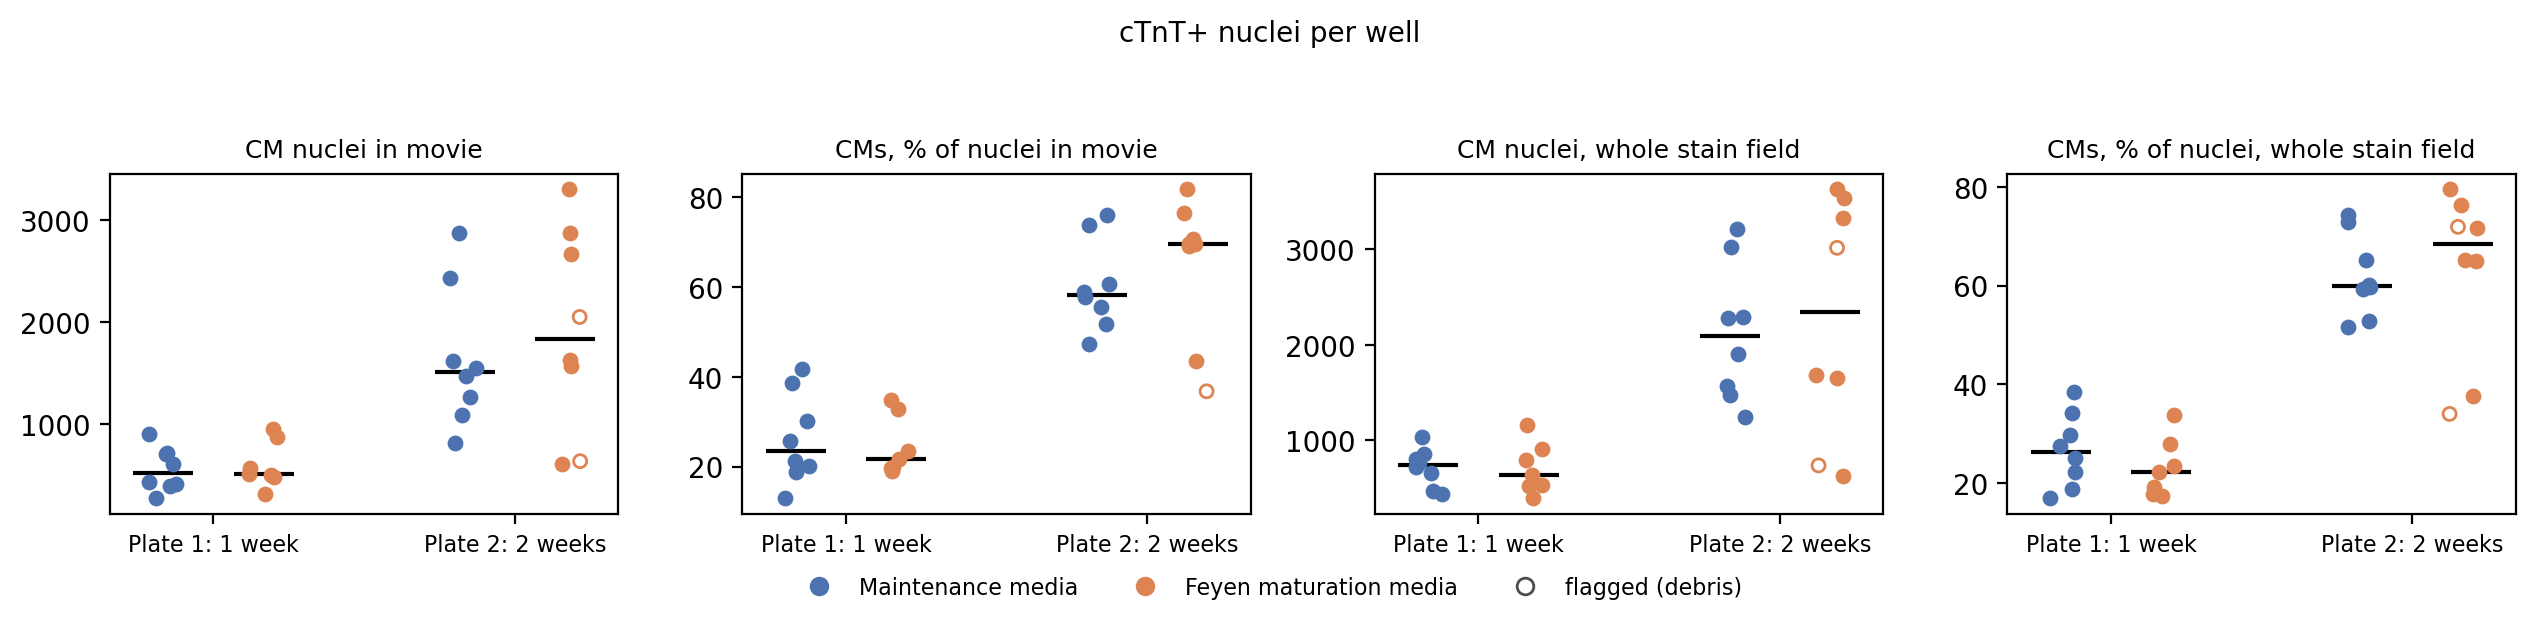

,Plate,Well,Condition,n_nuclei,n_cm,n_nuclei_stain,n_cm_stain,pct_cm,pct_cm_stain,flagged
0,plate1,B02,Maintenance media,1869,723,2354,803,38.7,34.1,
1,plate1,B03,Maintenance media,2138,277,2966,660,13.0,22.3,
2,plate1,B04,Maintenance media,2178,906,2686,1034,41.6,38.5,
3,plate1,B05,Maintenance media,2312,433,2796,474,18.7,17.0,
4,plate1,B06,Maintenance media,2376,609,3060,765,25.6,25.0,
5,plate1,B07,Maintenance media,1935,412,2303,433,21.3,18.8,
6,plate1,B08,Maintenance media,2356,710,2883,857,30.1,29.7,
7,plate1,B09,Maintenance media,1972,399,2632,722,20.2,27.4,
8,plate1,C02,Feyen maturation media,1687,319,2207,394,18.9,17.9,
9,plate1,C03,Feyen maturation media,2682,877,3252,910,32.7,28.0,


In [4]:
cm_counts = summarize_cm_counts(features, classification)
cm_counts.to_csv(CALCIUM_DIR / f"well_summary_{PREFIX}counts.csv", index=False)
cm_count_fig = plot_well_metrics(cm_counts, metrics=CM_METRICS, title="cTnT+ nuclei per well",
                                 export_name="well-cm-counts")
cm_counts.round(1)

#### Example traces (CMs only)
Same wells as notebook 5. Red = the 3 highest-peak CMs, grey = 5 random "beating" CMs, black = mean of all CMs in the well.

Exported: ../../Calcium/figures/CM_plate1_example-traces.png


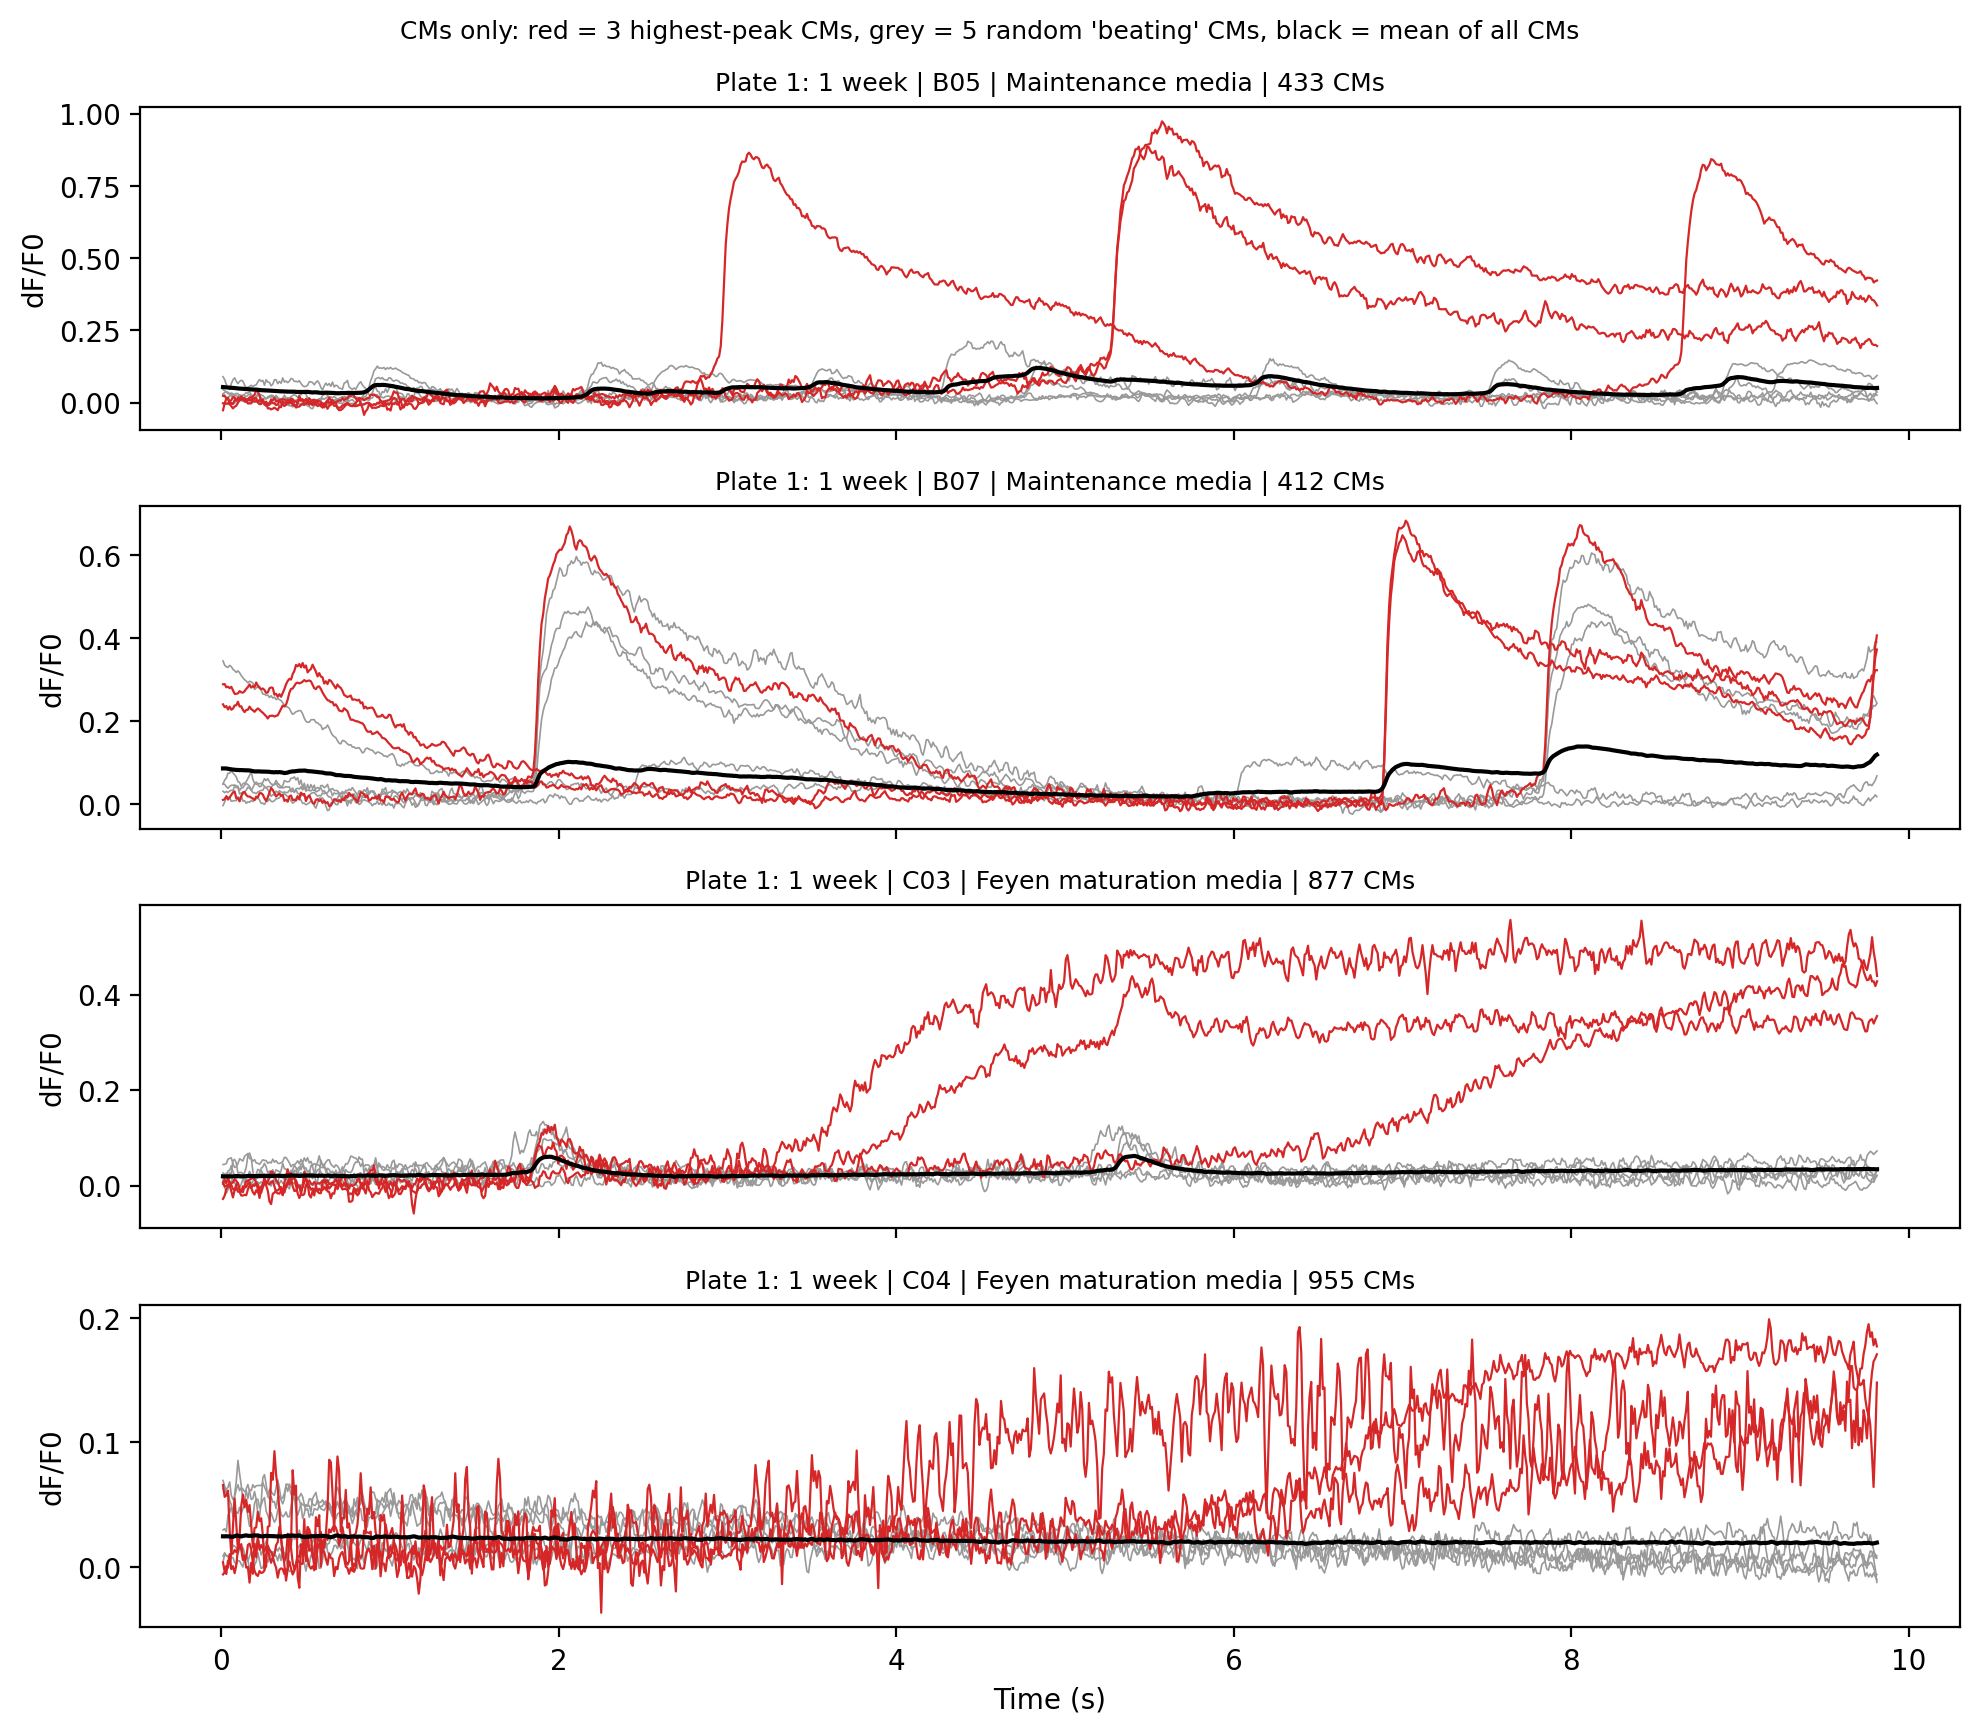

In [5]:
# Plate 1: 1 week in assigned media
plate1_examples = plot_example_traces(
    plate="plate1",
    wells=["B05", "B07", "C03", "C04"],
    features=features,
    n_top=3,
    n_random=5,
    export_name="plate1_example-traces",
)

Exported: ../../Calcium/figures/CM_plate2_example-traces.png


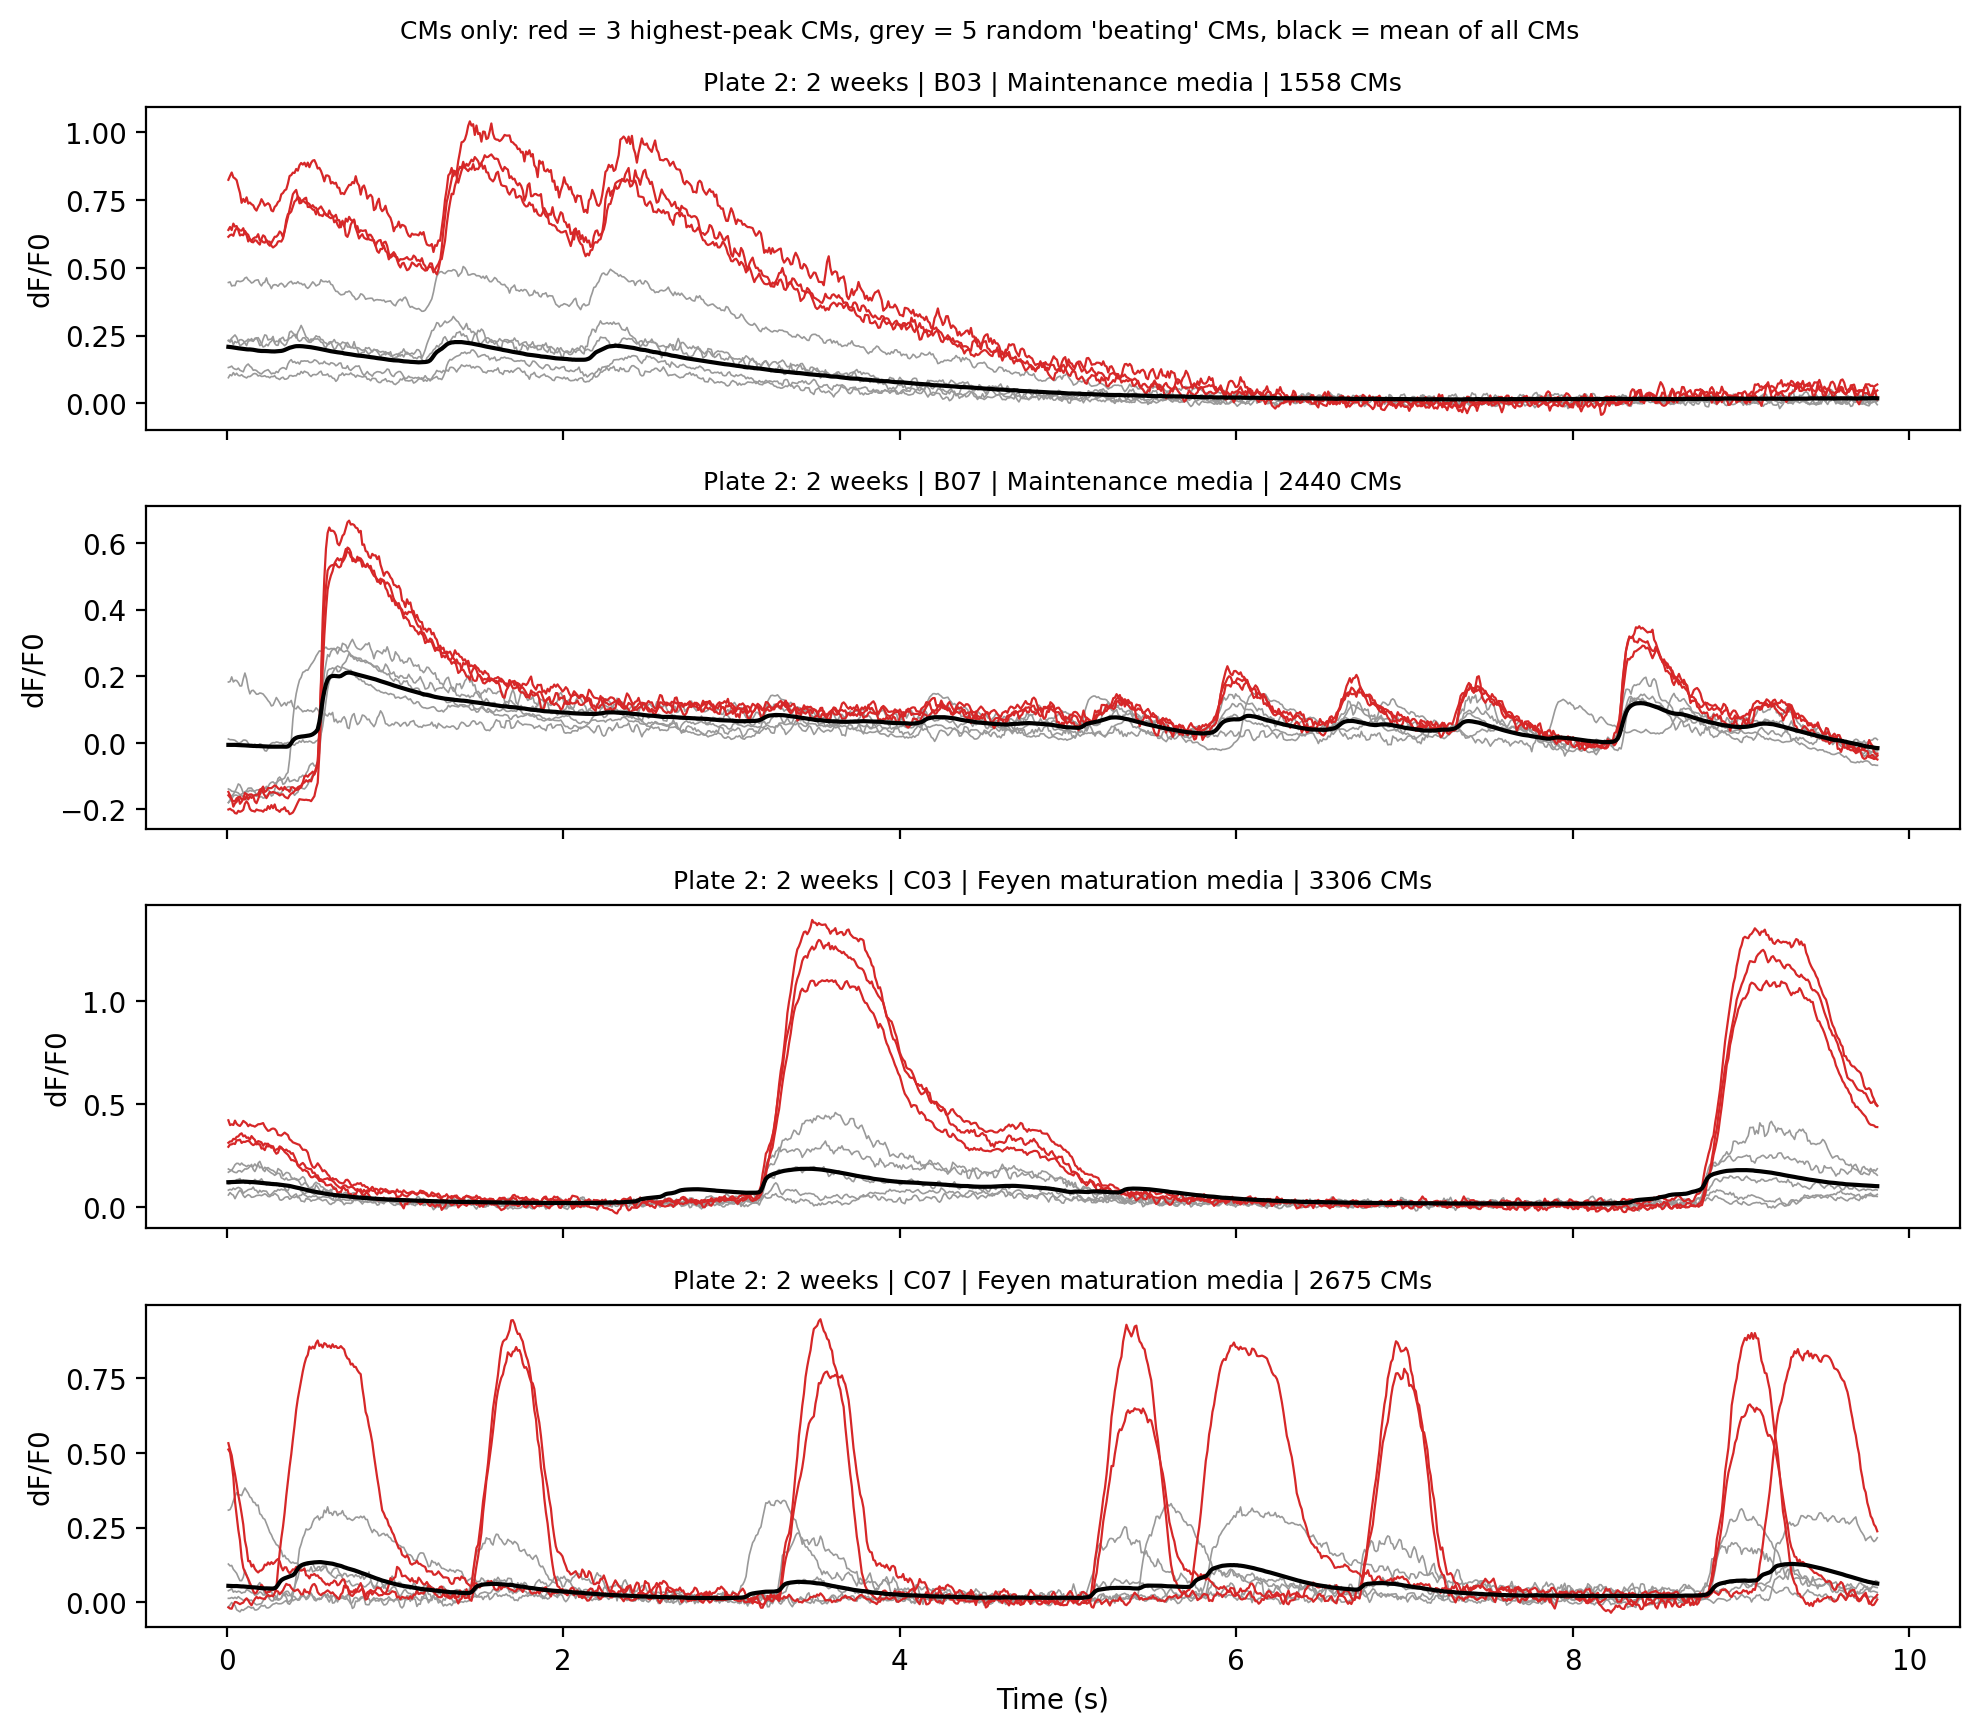

In [6]:
# Plate 2: 2 weeks in assigned media
plate2_examples = plot_example_traces(
    plate="plate2",
    wells=["B03", "B07", "C03", "C07"],
    features=features,
    n_top=3,
    n_random=5,
    export_name="plate2_example-traces",
)

#### Mean traces across each plate
Plate layout: rows = conditions, columns = wells. Black = mean of all CMs; red = mean of the top 10% of CMs by peak dF/F0; grey = mean of the non-CM nuclei, for contrast.

Exported: ../../Calcium/figures/CM_plate1_mean-traces.png


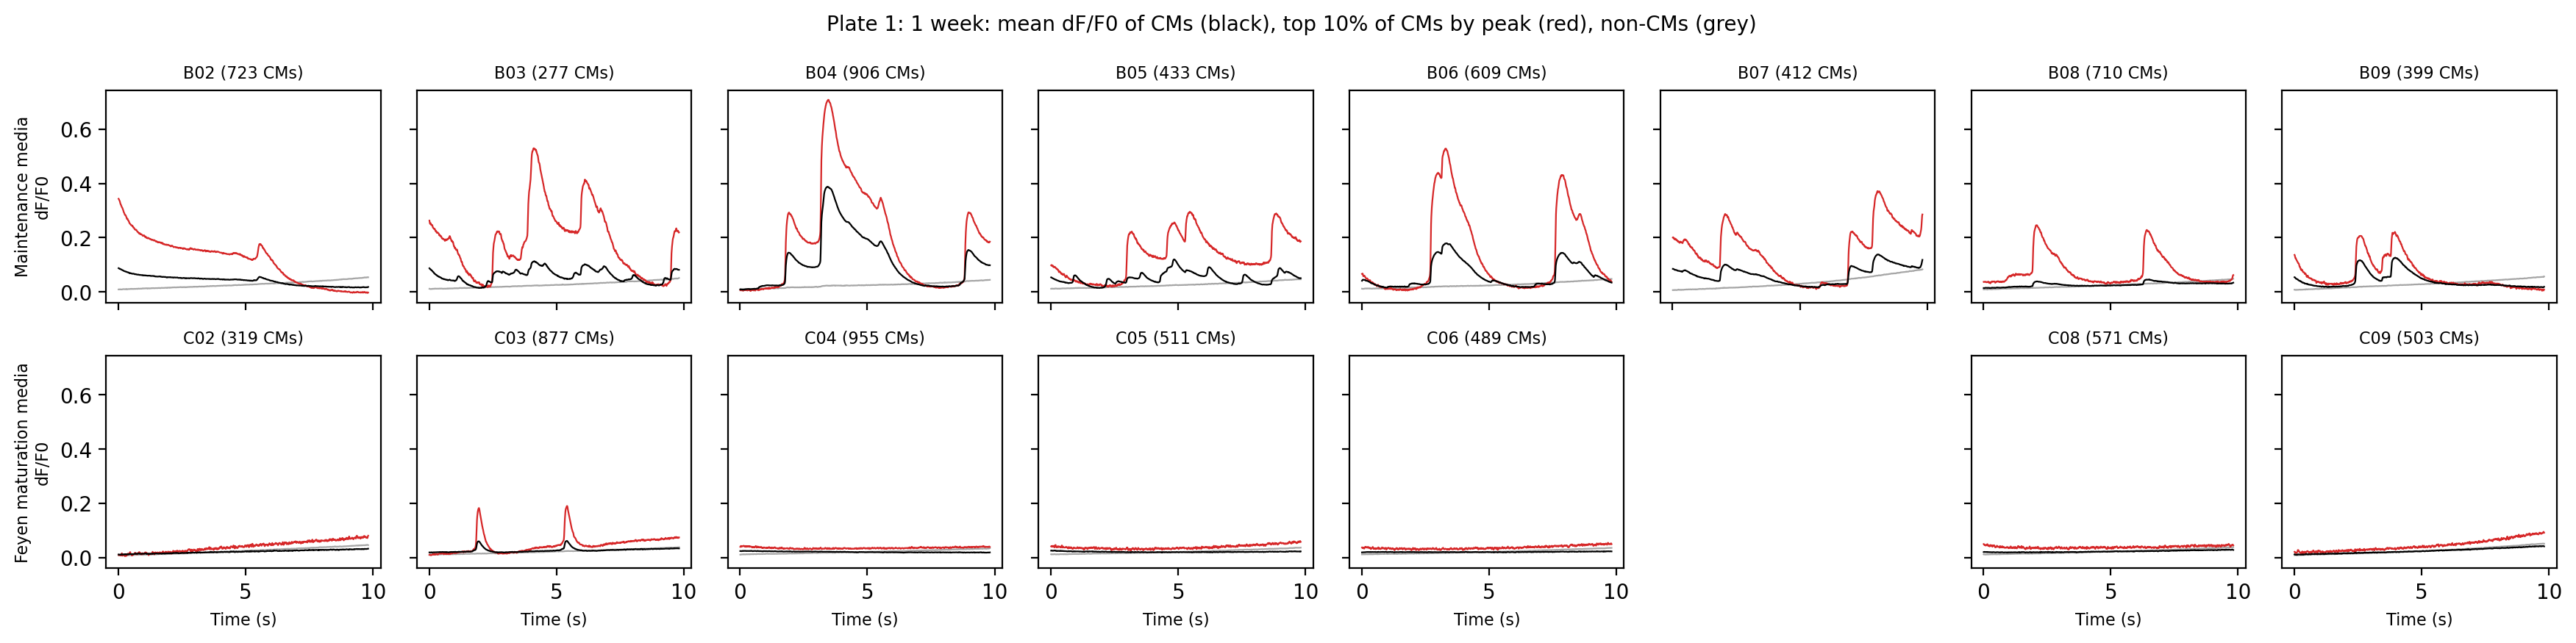

In [7]:
# Plate 1: 1 week in assigned media
plate1_means = plot_plate_mean_traces("plate1", features, top_frac=0.1, export_name="plate1_mean-traces")

Exported: ../../Calcium/figures/CM_plate2_mean-traces.png


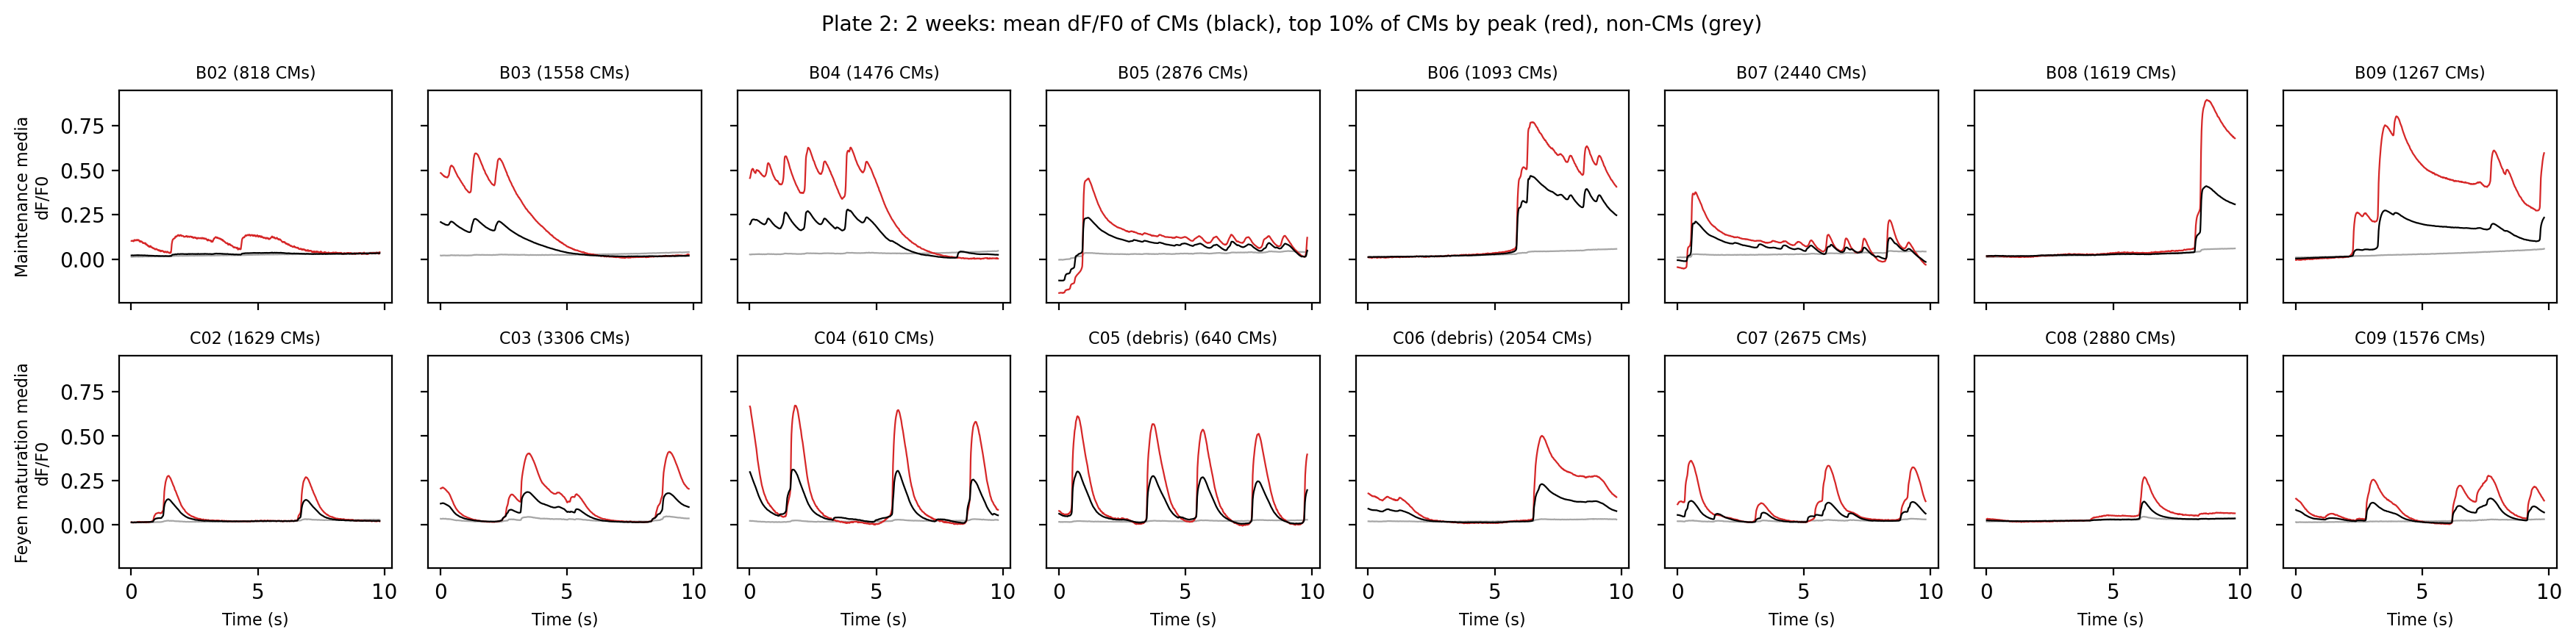

In [8]:
# Plate 2: 2 weeks in assigned media
plate2_means = plot_plate_mean_traces("plate2", features, top_frac=0.1, export_name="plate2_mean-traces")

#### Heatmaps and spatial maps (CMs only)
One well per condition. Heatmap rows are CMs sorted by peak dF/F0; the spatial map places each CM where it sits in the calcium movie (non-CMs in light grey).

Exported: ../../Calcium/figures/CM_plate2_B03_heatmap.png


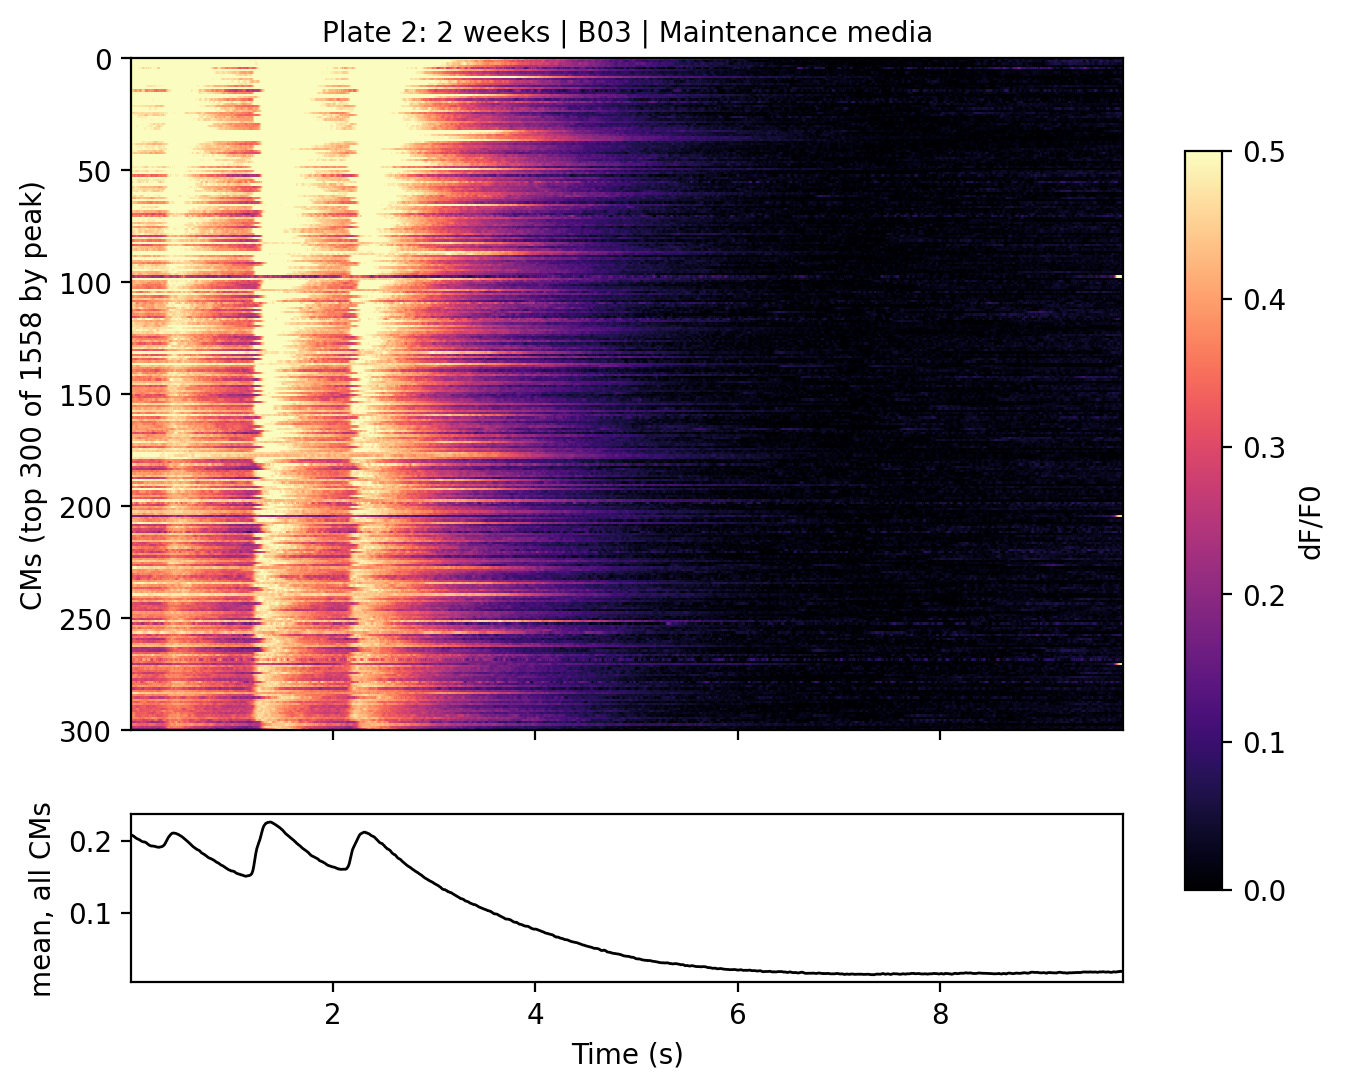

Exported: ../../Calcium/figures/CM_plate2_B03_peak-map.png


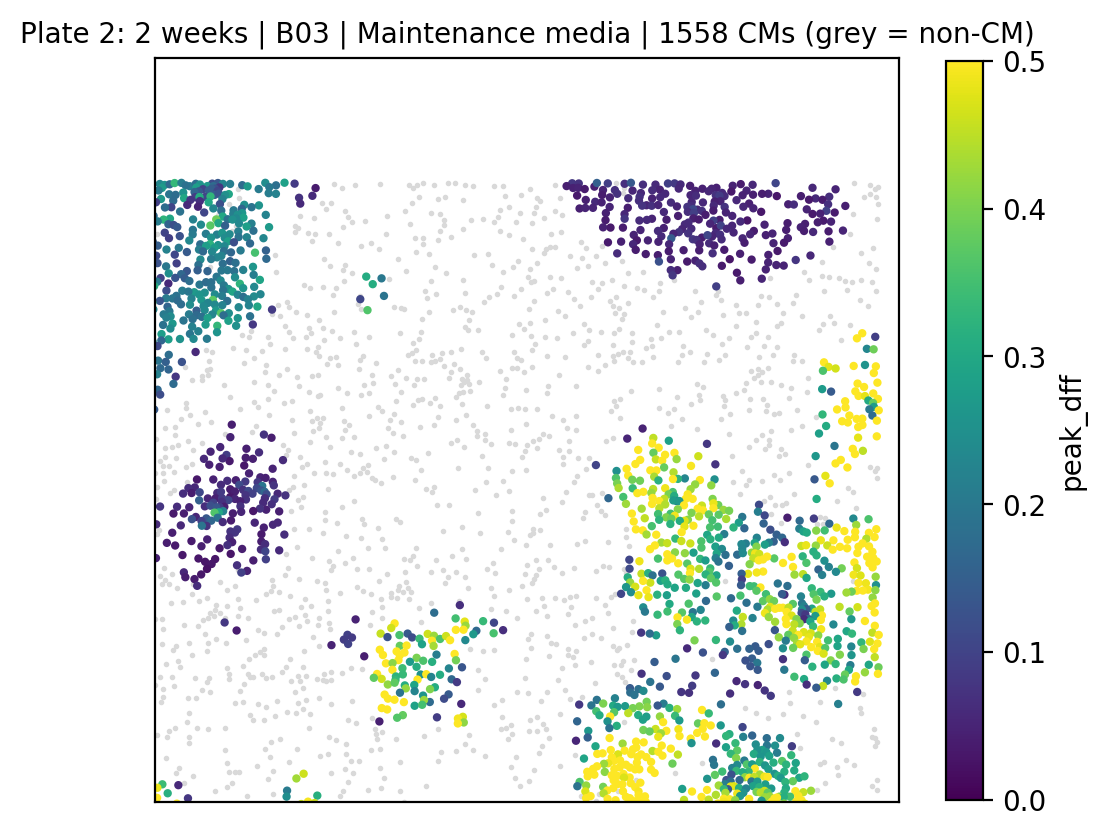

Exported: ../../Calcium/figures/CM_plate2_C03_heatmap.png


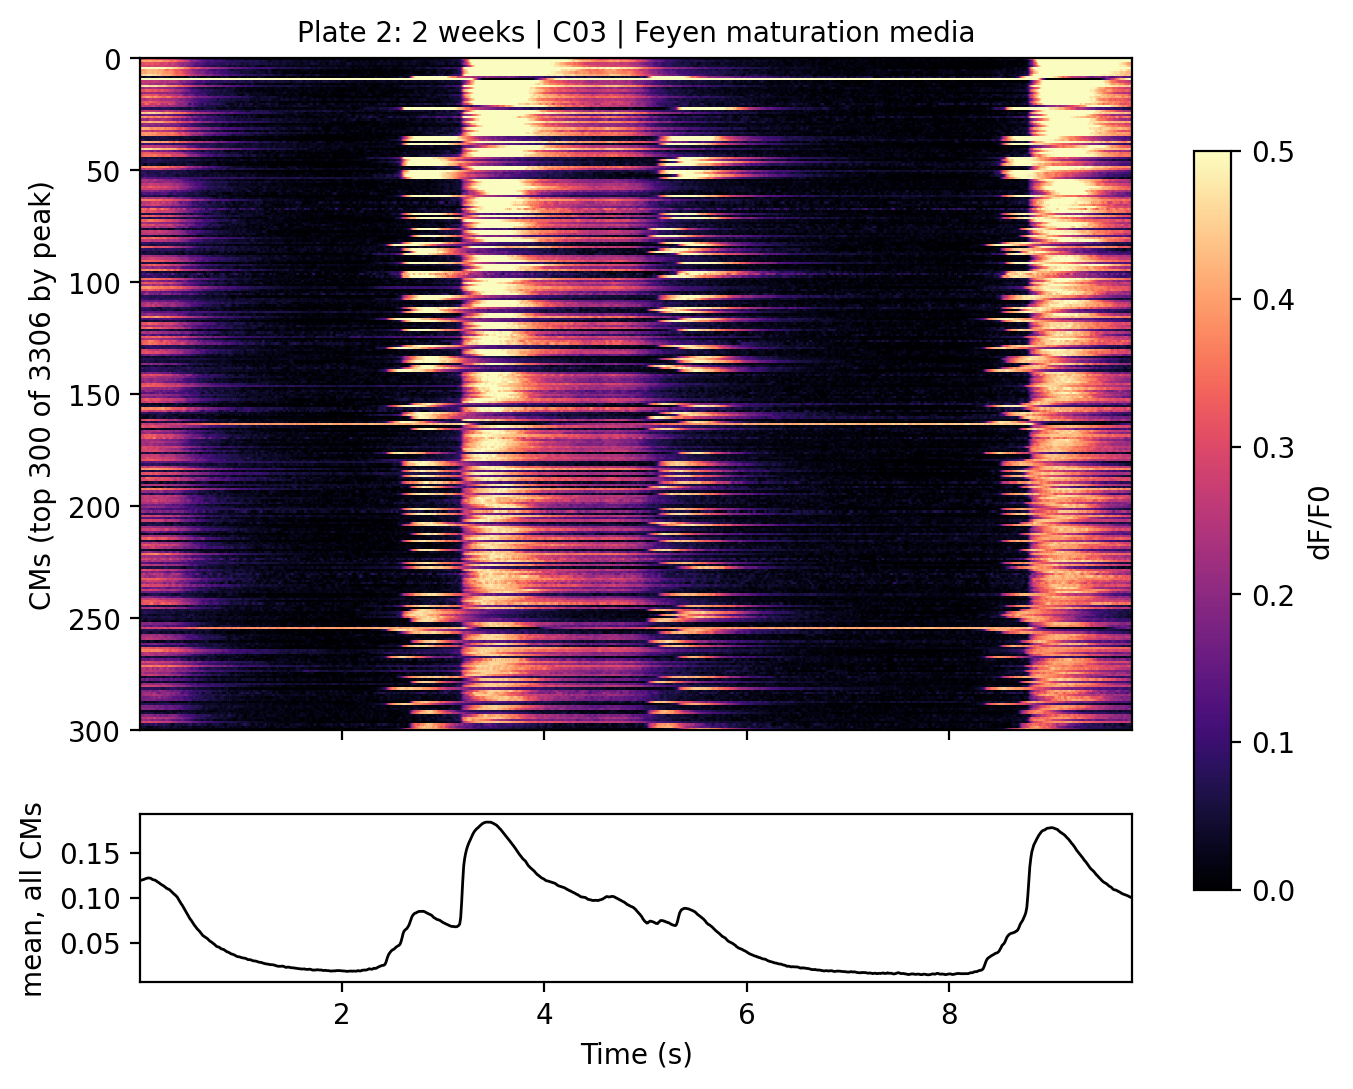

Exported: ../../Calcium/figures/CM_plate2_C03_peak-map.png


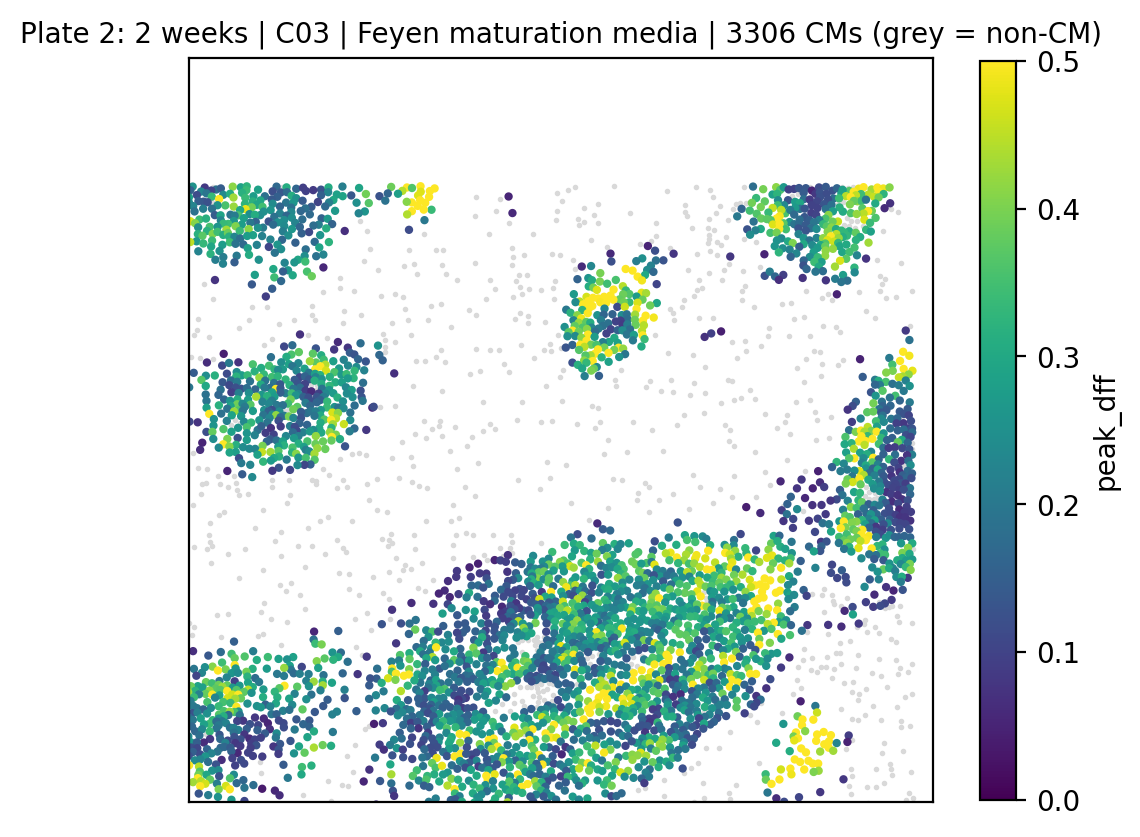

In [9]:
# Plate 2: maintenance (B03) vs. Feyen (C03)
for well in ["B03", "C03"]:
    plot_trace_heatmap("plate2", well, features, n_show=300, vmax=0.5, export_name=f"plate2_{well}_heatmap")
    plot_spatial_map("plate2", well, features, metric="peak_dff", vmax=0.5, export_name=f"plate2_{well}_peak-map")

#### Aligned transients (CMs only)
**Why align?** The cells beat spontaneously, so each CM fires at its own moment in the 9.8 s movie. Averaging raw traces over time lines up a rising edge in one cell with a decay or a baseline in another, and the average smears into a low, broad bump that looks like no real transient. If each transient is first shifted so that its start sits at t = 0, the average keeps the true shape: the rise, the peak, and the decay. This is how Alex's pipeline (`6-plot_features.py`) shows transient shape per condition.

**What is plotted.**
- **Which nuclei:** active CMs only (cTnT+, >= 2 peaks, peak dF/F0 >= 0.2). The trace is dF/F0 from `calcium.dff()` with the pipeline defaults, so amplitudes are comparable across wells.
- **Which transient:** each nucleus's first *complete, full-size* transient. Full-size means its amplitude is at least 50% of that nucleus's largest transient (`ALIGN_MIN_REL`). Without this rule, many active CMs contribute a small noise-level blip that happens to come before their real transient, and some well means go flat. Complete means its whole window (50 frames before to 350 after the start, about -0.5 to +3.4 s) lies inside the movie. A transient that starts too close to either end is skipped in favour of the next one. The window easily covers the longest transients (Plate 2 Feyen D90 ~1.2 s).
- **Alignment point (t = 0):** the first frame where the rise passes **10% of that transient's amplitude** above its local baseline (the minimum since the previous peak, as in `calcium.kinetics()`). This is the start of the rise, so the overlay shows the whole upstroke. (The small notch just before t = 0 in the means is a side effect of aligning on a noisy crossing: the frame before the crossing is, by construction, at or near the local minimum.) `time_to_peak` in the tables is measured from the max upstroke velocity instead, which is later on the rise, so the two do not match exactly.
- **Sampling:** up to 50 transients per well, drawn at random with a fixed seed (`ALIGN_SEED = 0`) so the figure is reproducible.

**How to read it.**
- **Per-plate figures:** rows are conditions, columns are wells. Grey = individual transients, black = their mean, dashed red line = t = 0. Each title gives n shown of n complete transients. Debris wells (Plate 2 C05, C06) are marked in red. Tight grey bundles mean the cells in that well share one shape. A late second bump means the next beat arrived inside the window, which happens in the fast wells (~0.7-0.8 Hz).
- **Summary figure:** one line per condition, the mean of the per-well means, so each well counts once. The band is +/- 1 SD across wells. Only wells with >= 5 transients are included, and the legend gives the n. The bottom row scales each well mean to baseline 0 and peak 1 (peak taken within 1 s of t = 0), so differences in shape (rise speed, width, decay) show without amplitude. Compare Feyen vs. maintenance within a plate; across plates, time in media is mixed with imaging day.
- Plate 1 Feyen has almost no active CMs, so its panels hold only a handful of transients (or none). Do not read shape from them.

In [10]:
# Aligned windows for every well (seeded sample of up to 50 per well)
aligned = collect_aligned(features)
pd.DataFrame([{"Plate": p, "Well": w, "active_CMs": a["n_active"], "complete_transients": a["n_complete"],
               "shown": len(a["traces"])} for (p, w), a in aligned.items()]).pivot_table(
    index="Well", columns="Plate", values=["active_CMs", "complete_transients", "shown"])

active_CMs         complete_transients          shown       
Plate     plate1  plate2              plate1  plate2 plate1 plate2
Well                                                              
B02        130.0    23.0               130.0    23.0   50.0   23.0
B03         72.0   878.0                72.0   878.0   50.0   50.0
B04        682.0  1060.0               682.0  1060.0   50.0   50.0
B05        165.0  2177.0               165.0  1770.0   50.0   50.0
B06        296.0   935.0               264.0   935.0   50.0   50.0
B07        186.0  1766.0               117.0   643.0   50.0   50.0
B08         52.0   885.0                52.0    10.0   50.0   10.0
B09        172.0   546.0               172.0   546.0   50.0   50.0
C02          0.0   550.0                 0.0   550.0    0.0   50.0
C03         60.0  2155.0                60.0  2155.0   50.0   50.0
C04          0.0   481.0                 0.0   481.0    0.0   50.0
C05          1.0   474.0                 1.0   474.0    1.0   50.0
C06          2.0  1177.0                 2.0   241.0    2.0   50.0
C07          NaN  1201.0                 NaN  1201.0    NaN   50.0
C08          0.0   484.0                 0.0   483.0    0.0   50.0
C09          1.0   863.0                 1.0   510.0    1.0   50.0

Exported: ../../Calcium/figures/CM_aligned-transients_plate1.png


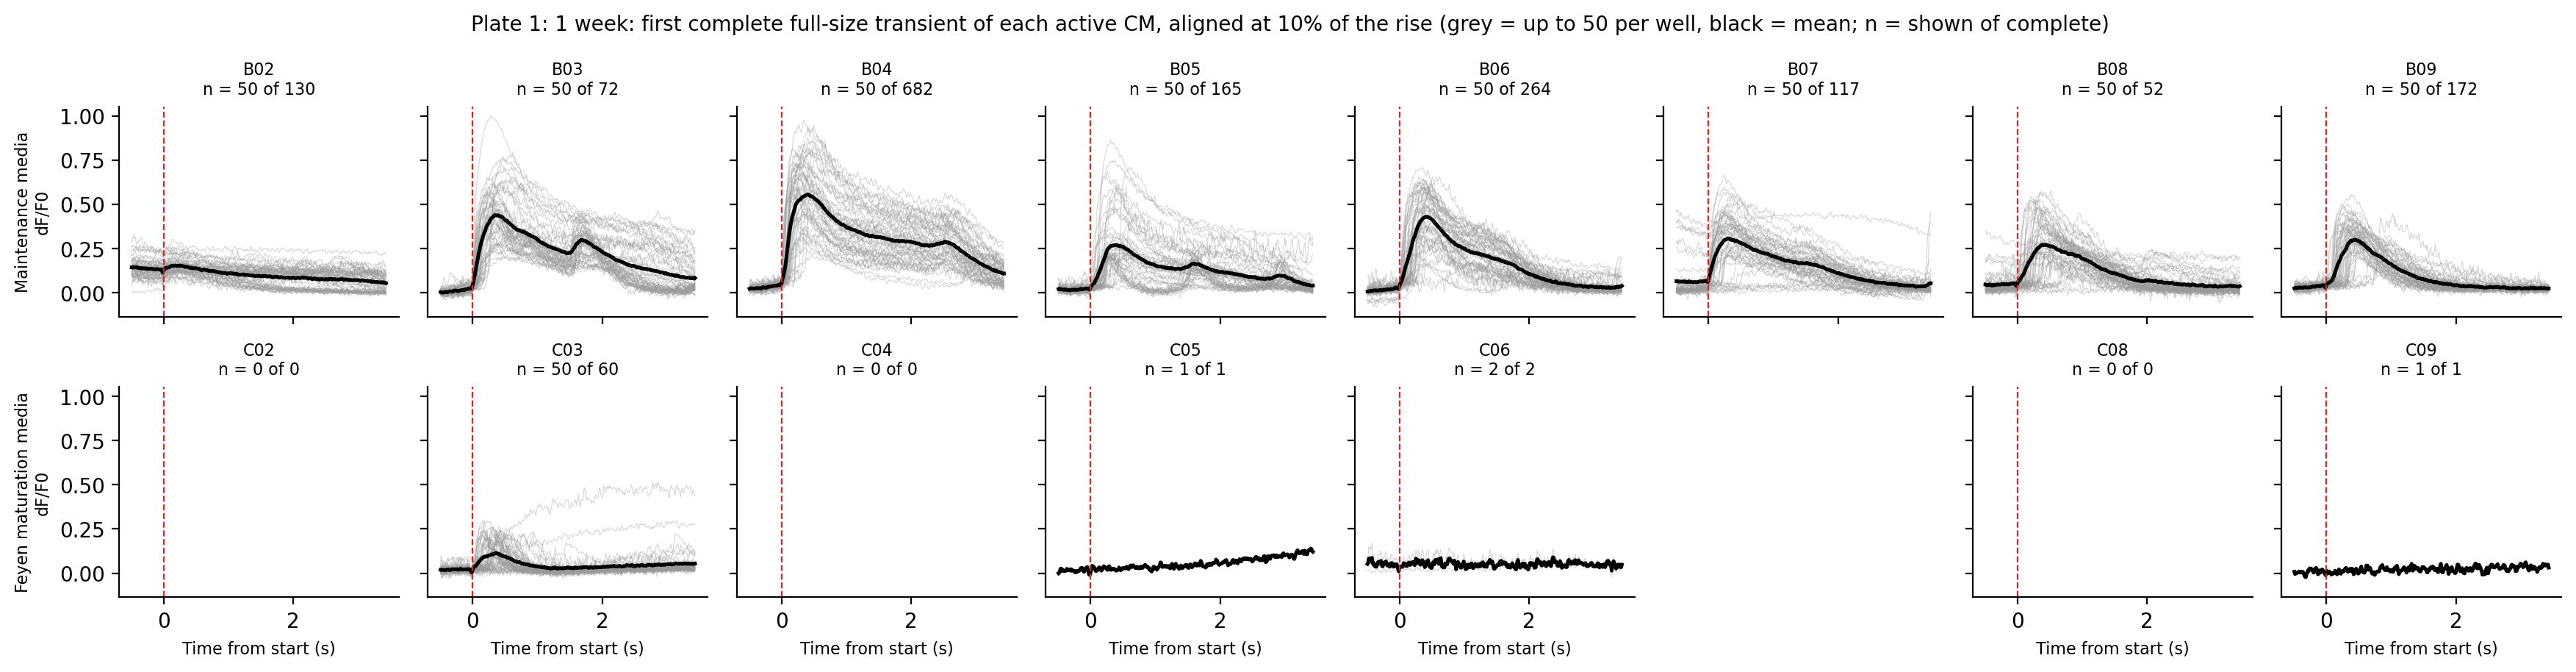

In [11]:
# Plate 1: 1 week in assigned media
plate1_aligned = plot_aligned_transients("plate1", aligned, export_name="aligned-transients_plate1")

Exported: ../../Calcium/figures/CM_aligned-transients_plate2.png


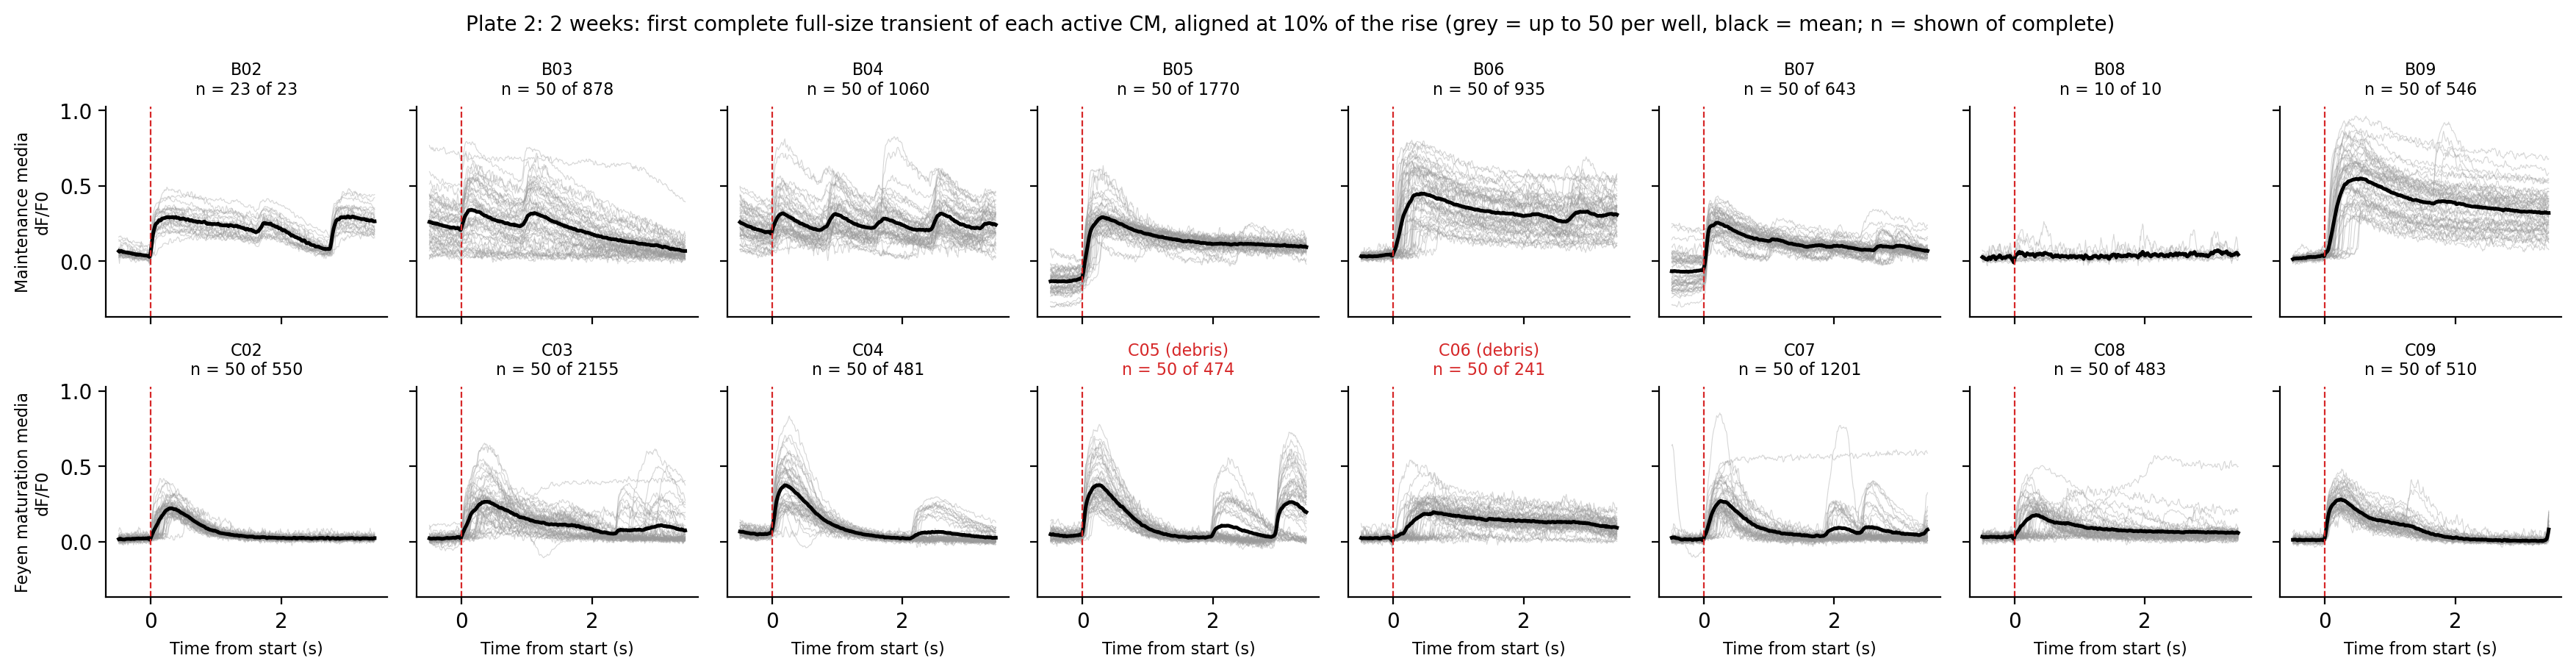

In [12]:
# Plate 2: 2 weeks in assigned media
plate2_aligned = plot_aligned_transients("plate2", aligned, export_name="aligned-transients_plate2")

Exported: ../../Calcium/figures/CM_aligned-transients_means.png


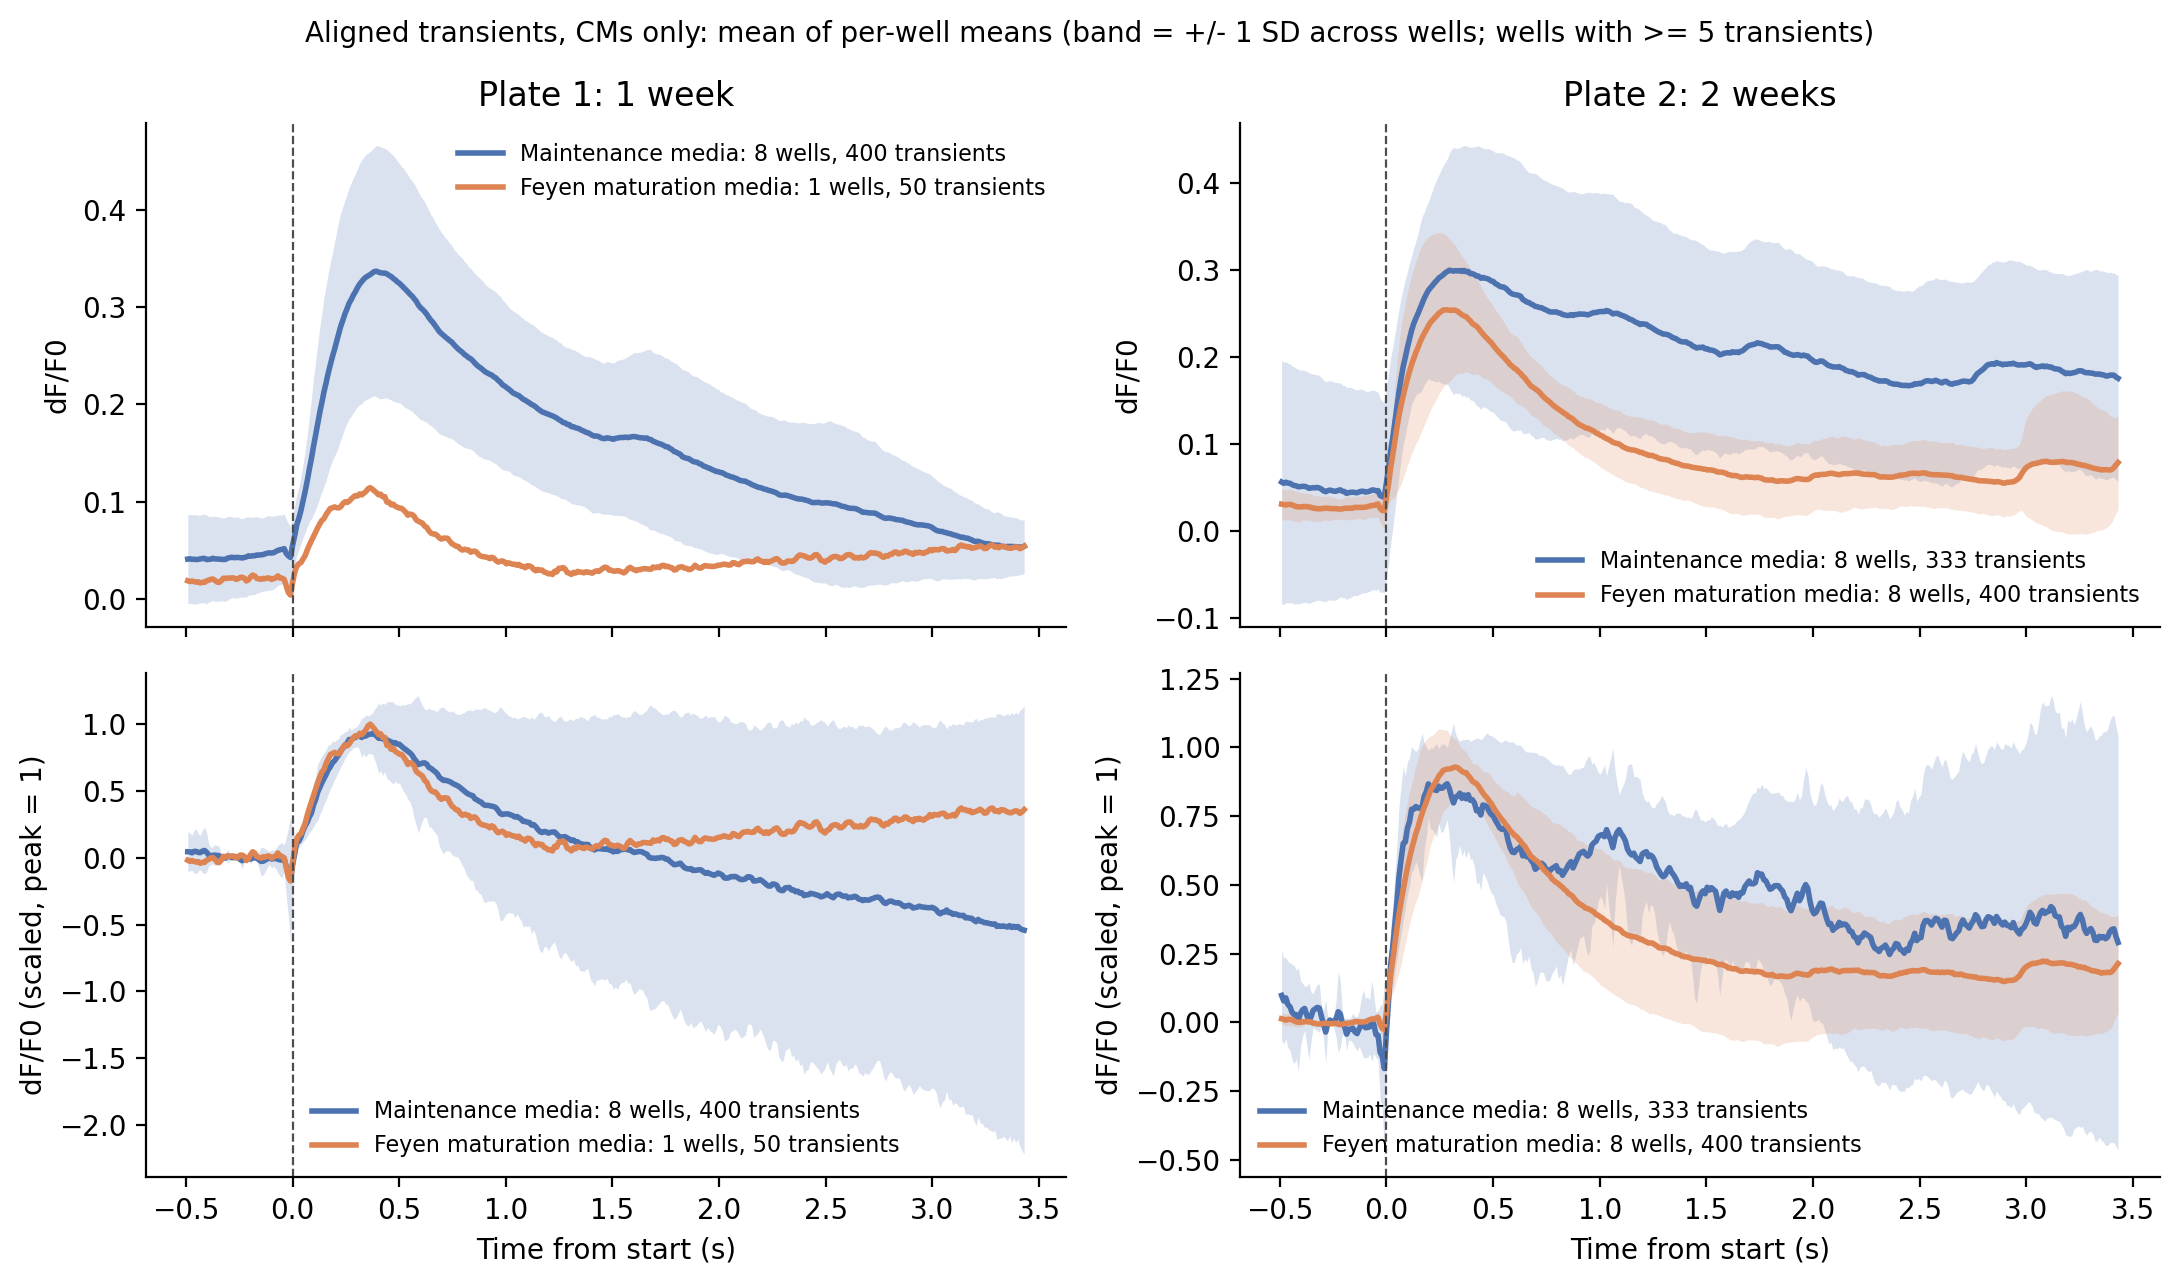

In [13]:
# Condition means, both plates
aligned_means = plot_aligned_means(aligned, export_name="aligned-transients_means")

#### Does the beat criterion still need the 0.2 placeholder?
Peak dF/F0 of every "beating" nucleus (>= 2 peaks at 5x its own noise), CMs (solid) vs. non-CMs (dashed). The dotted line is the notebook-5 placeholder `MIN_PEAK_DFF = 0.2`. The table gives, per group, the % of nuclei that pass ">= 2 peaks", and the % of those that also reach peak dF/F0 >= 0.2.

Exported: ../../Calcium/figures/CM_peak-dff-distributions.png


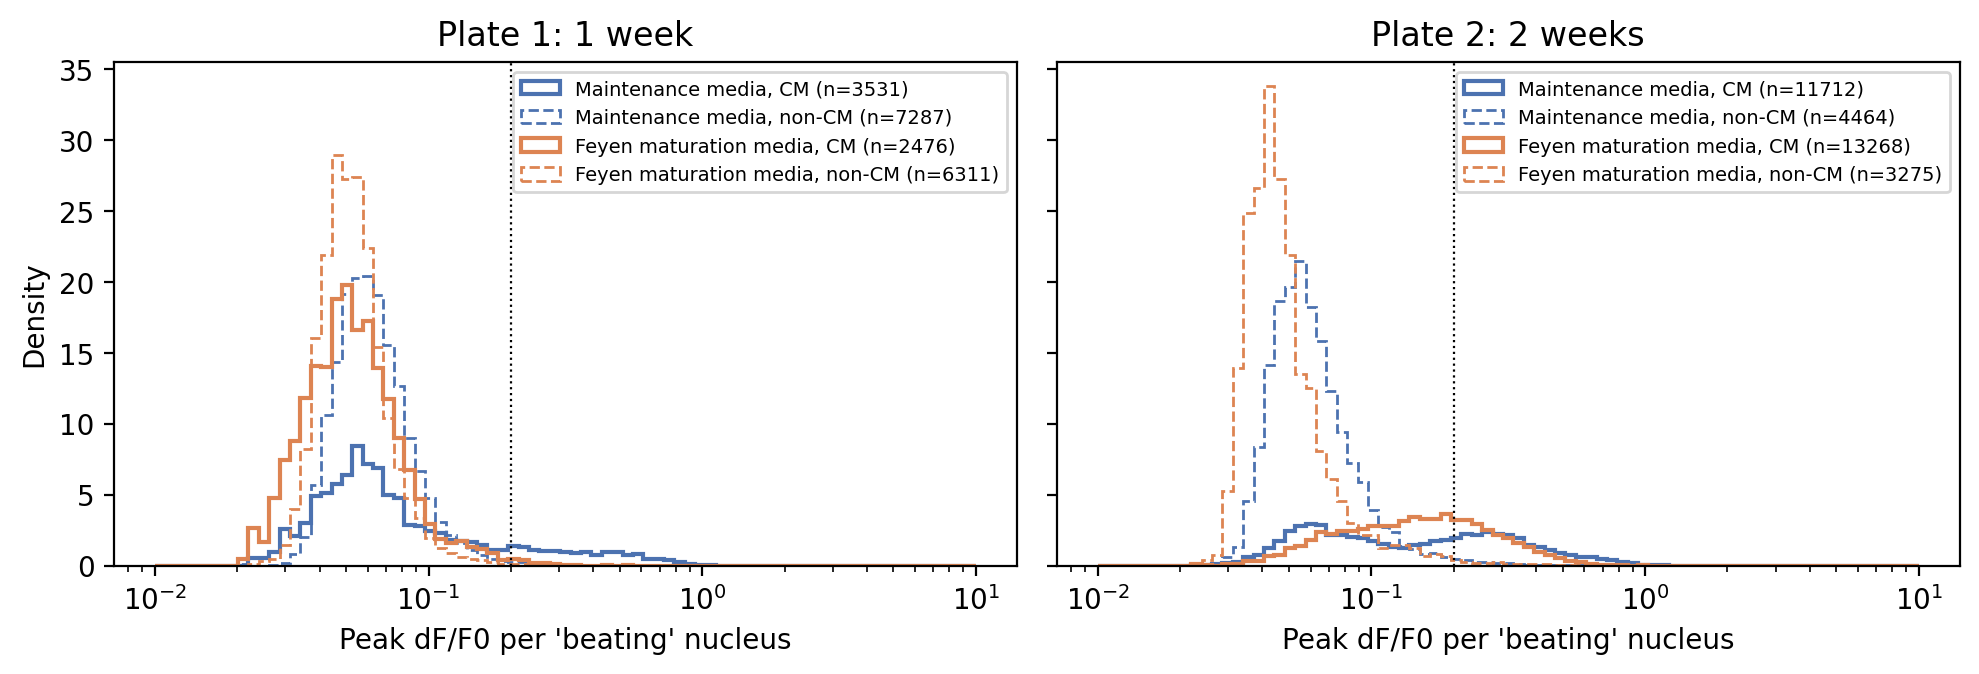

nuclei  pct_beating  pct_active  \
Plate  Condition              cTnT_pos                                    
plate1 Maintenance media      False      12667         57.5         1.1   
                              True        4469         79.0        39.3   
       Feyen maturation media False      12745         49.5         0.4   
                              True        4225         58.6         1.5   
plate2 Maintenance media      False       7992         55.9         2.9   
                              True       13147         89.1        62.9   
       Feyen maturation media False       7006         46.7         2.1   
                              True       15370         86.3        48.0   

                                        pct_of_beating_that_pass_0.2  
Plate  Condition              cTnT_pos                                
plate1 Maintenance media      False                              1.9  
                              True                              49.7  
       Feyen maturation media False                              0.8  
                              True                               2.6  
plate2 Maintenance media      False                              5.2  
                              True                              70.6  
       Feyen maturation media False                              4.5  
                              True                              55.7

In [14]:
peak_distributions = plot_peak_distributions(features, min_peak_dff=MIN_PEAK_DFF, export_name="peak-dff-distributions")
beat_check = features.assign(active=features.beating & (features.peak_dff >= MIN_PEAK_DFF)).groupby(
    ["Plate", "Condition", "cTnT_pos"]).agg(
    nuclei=("beating", "size"),
    pct_beating=("beating", lambda b: 100 * b.mean()),
    pct_active=("active", lambda a: 100 * a.mean()),
)
beat_check["pct_of_beating_that_pass_0.2"] = 100 * beat_check.pct_active / beat_check.pct_beating
beat_check.reindex(CONDITIONS, level="Condition").round(1)

#### Per-well summaries (CMs only)
Each point is one well (median over its CMs). Two versions:
1. **All "beating" CMs** (>= 2 peaks, Alex's default).
2. **Active CMs only**: also require peak dF/F0 >= `MIN_PEAK_DFF` (0.2, the notebook-5 placeholder), to see whether it still changes anything once non-CMs are gone.

These are exploratory; no statistics yet (n = 7-8 wells per group).

Exported: ../../Calcium/figures/CM_well-metrics_beating.png


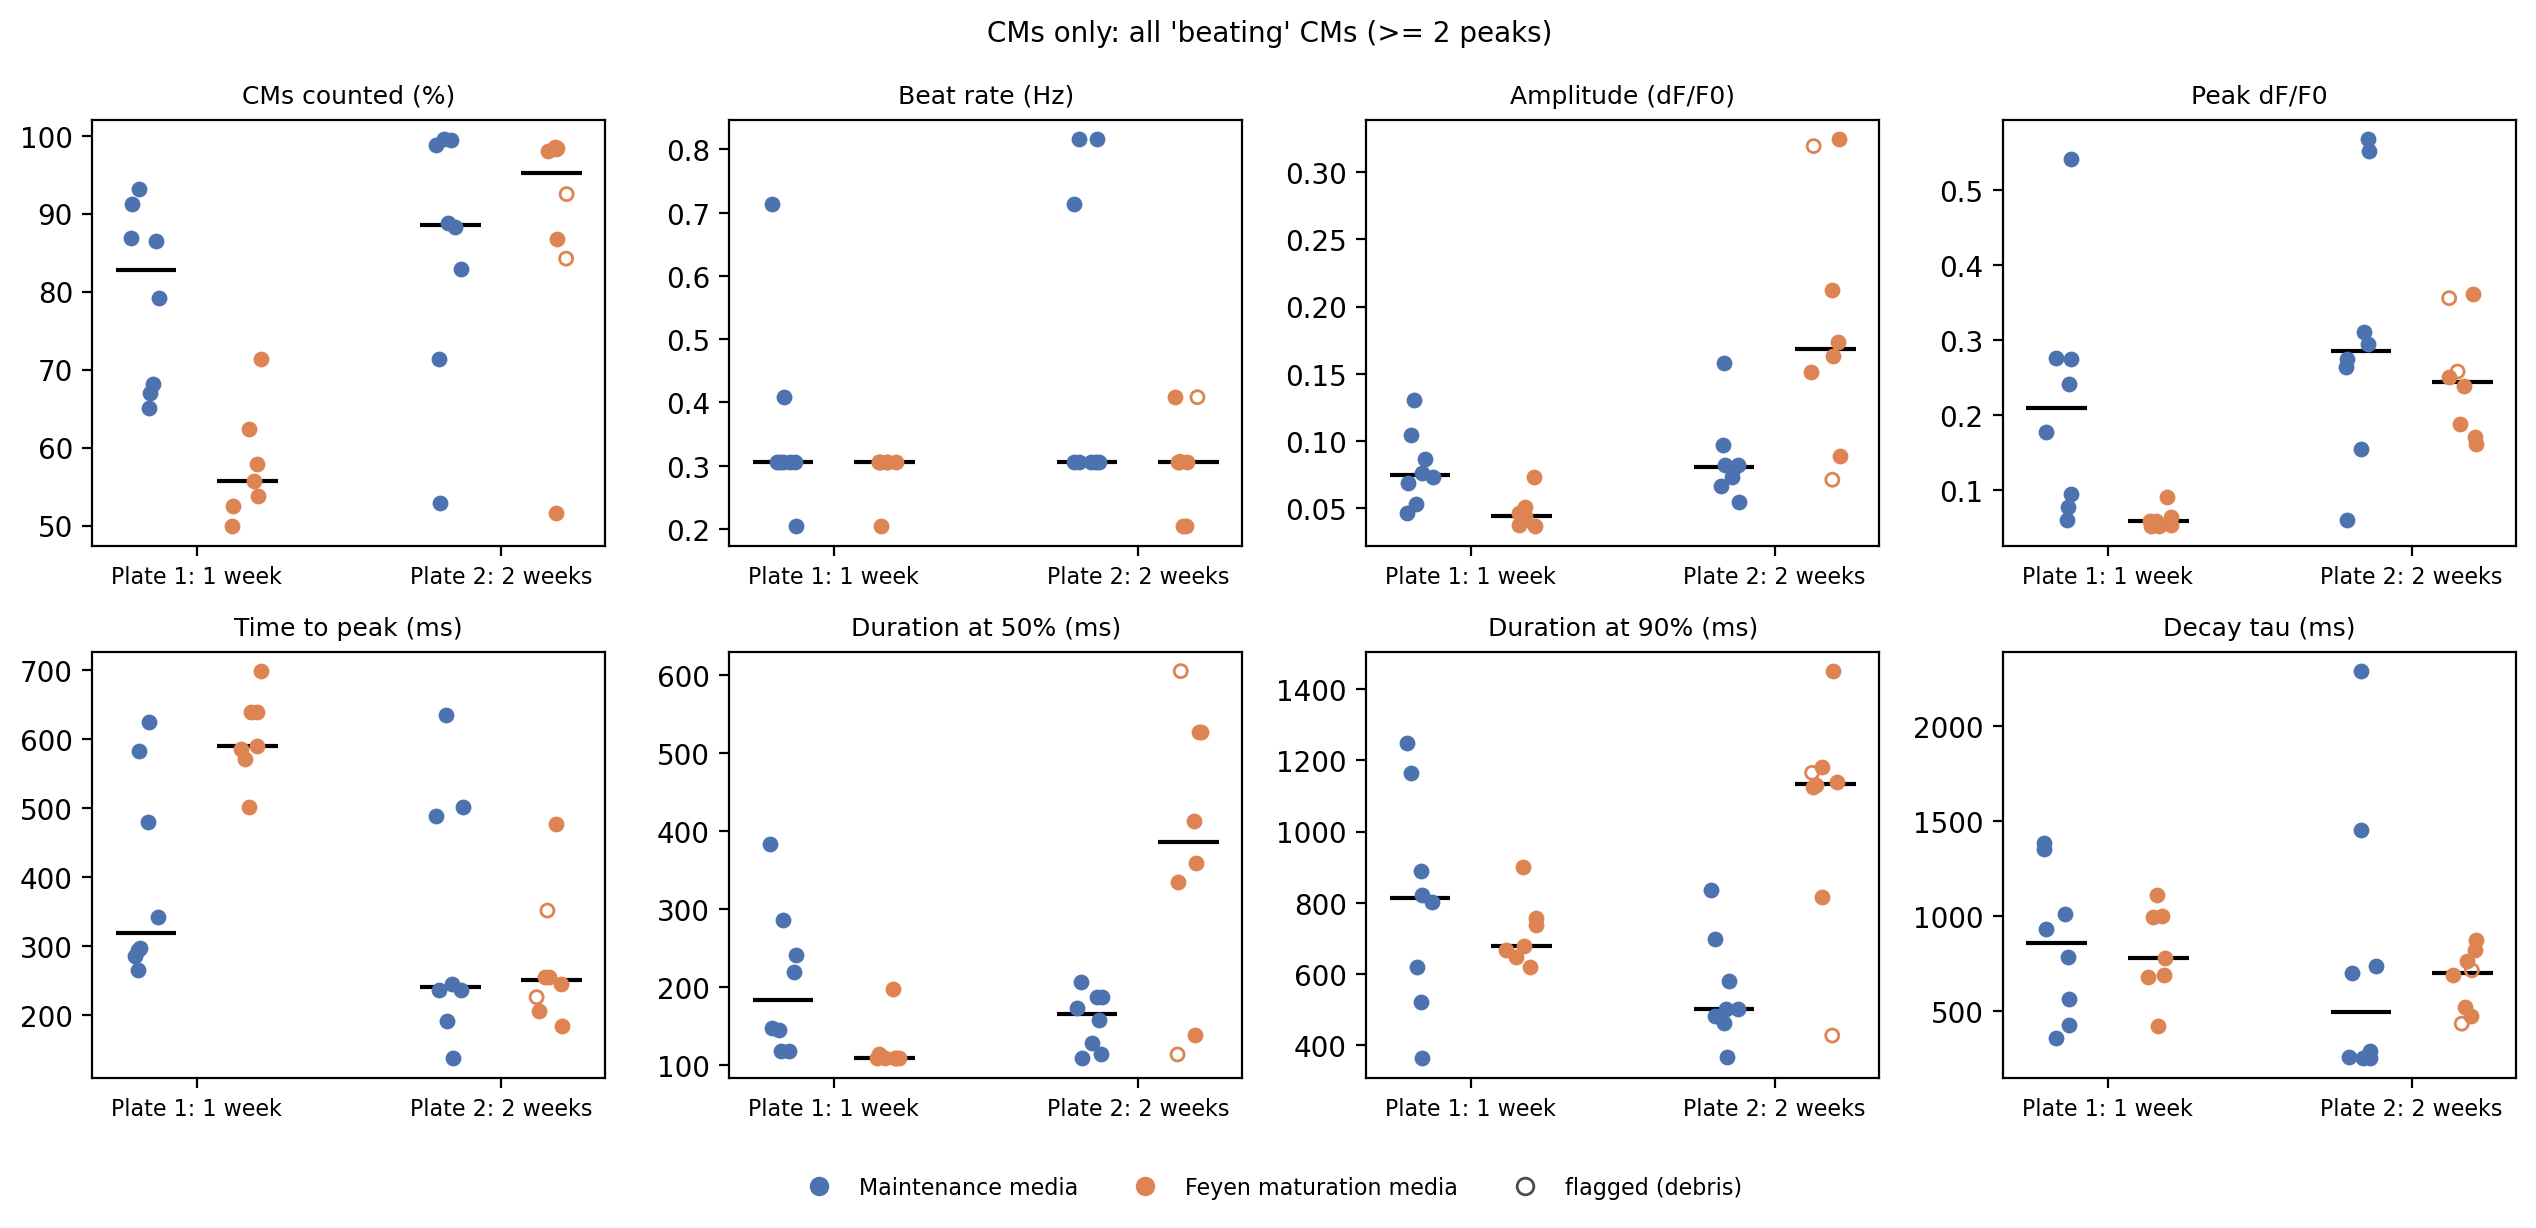

In [15]:
# Version 1: Alex's default "beating" definition, CMs only
summary_beating = summarize_wells(features)
summary_beating.to_csv(CALCIUM_DIR / f"well_summary_{PREFIX}beating.csv", index=False)
well_metrics_beating = plot_well_metrics(summary_beating, title="CMs only: all 'beating' CMs (>= 2 peaks)",
                                         export_name="well-metrics_beating")

Exported: ../../Calcium/figures/CM_well-metrics_active-peak0.2.png


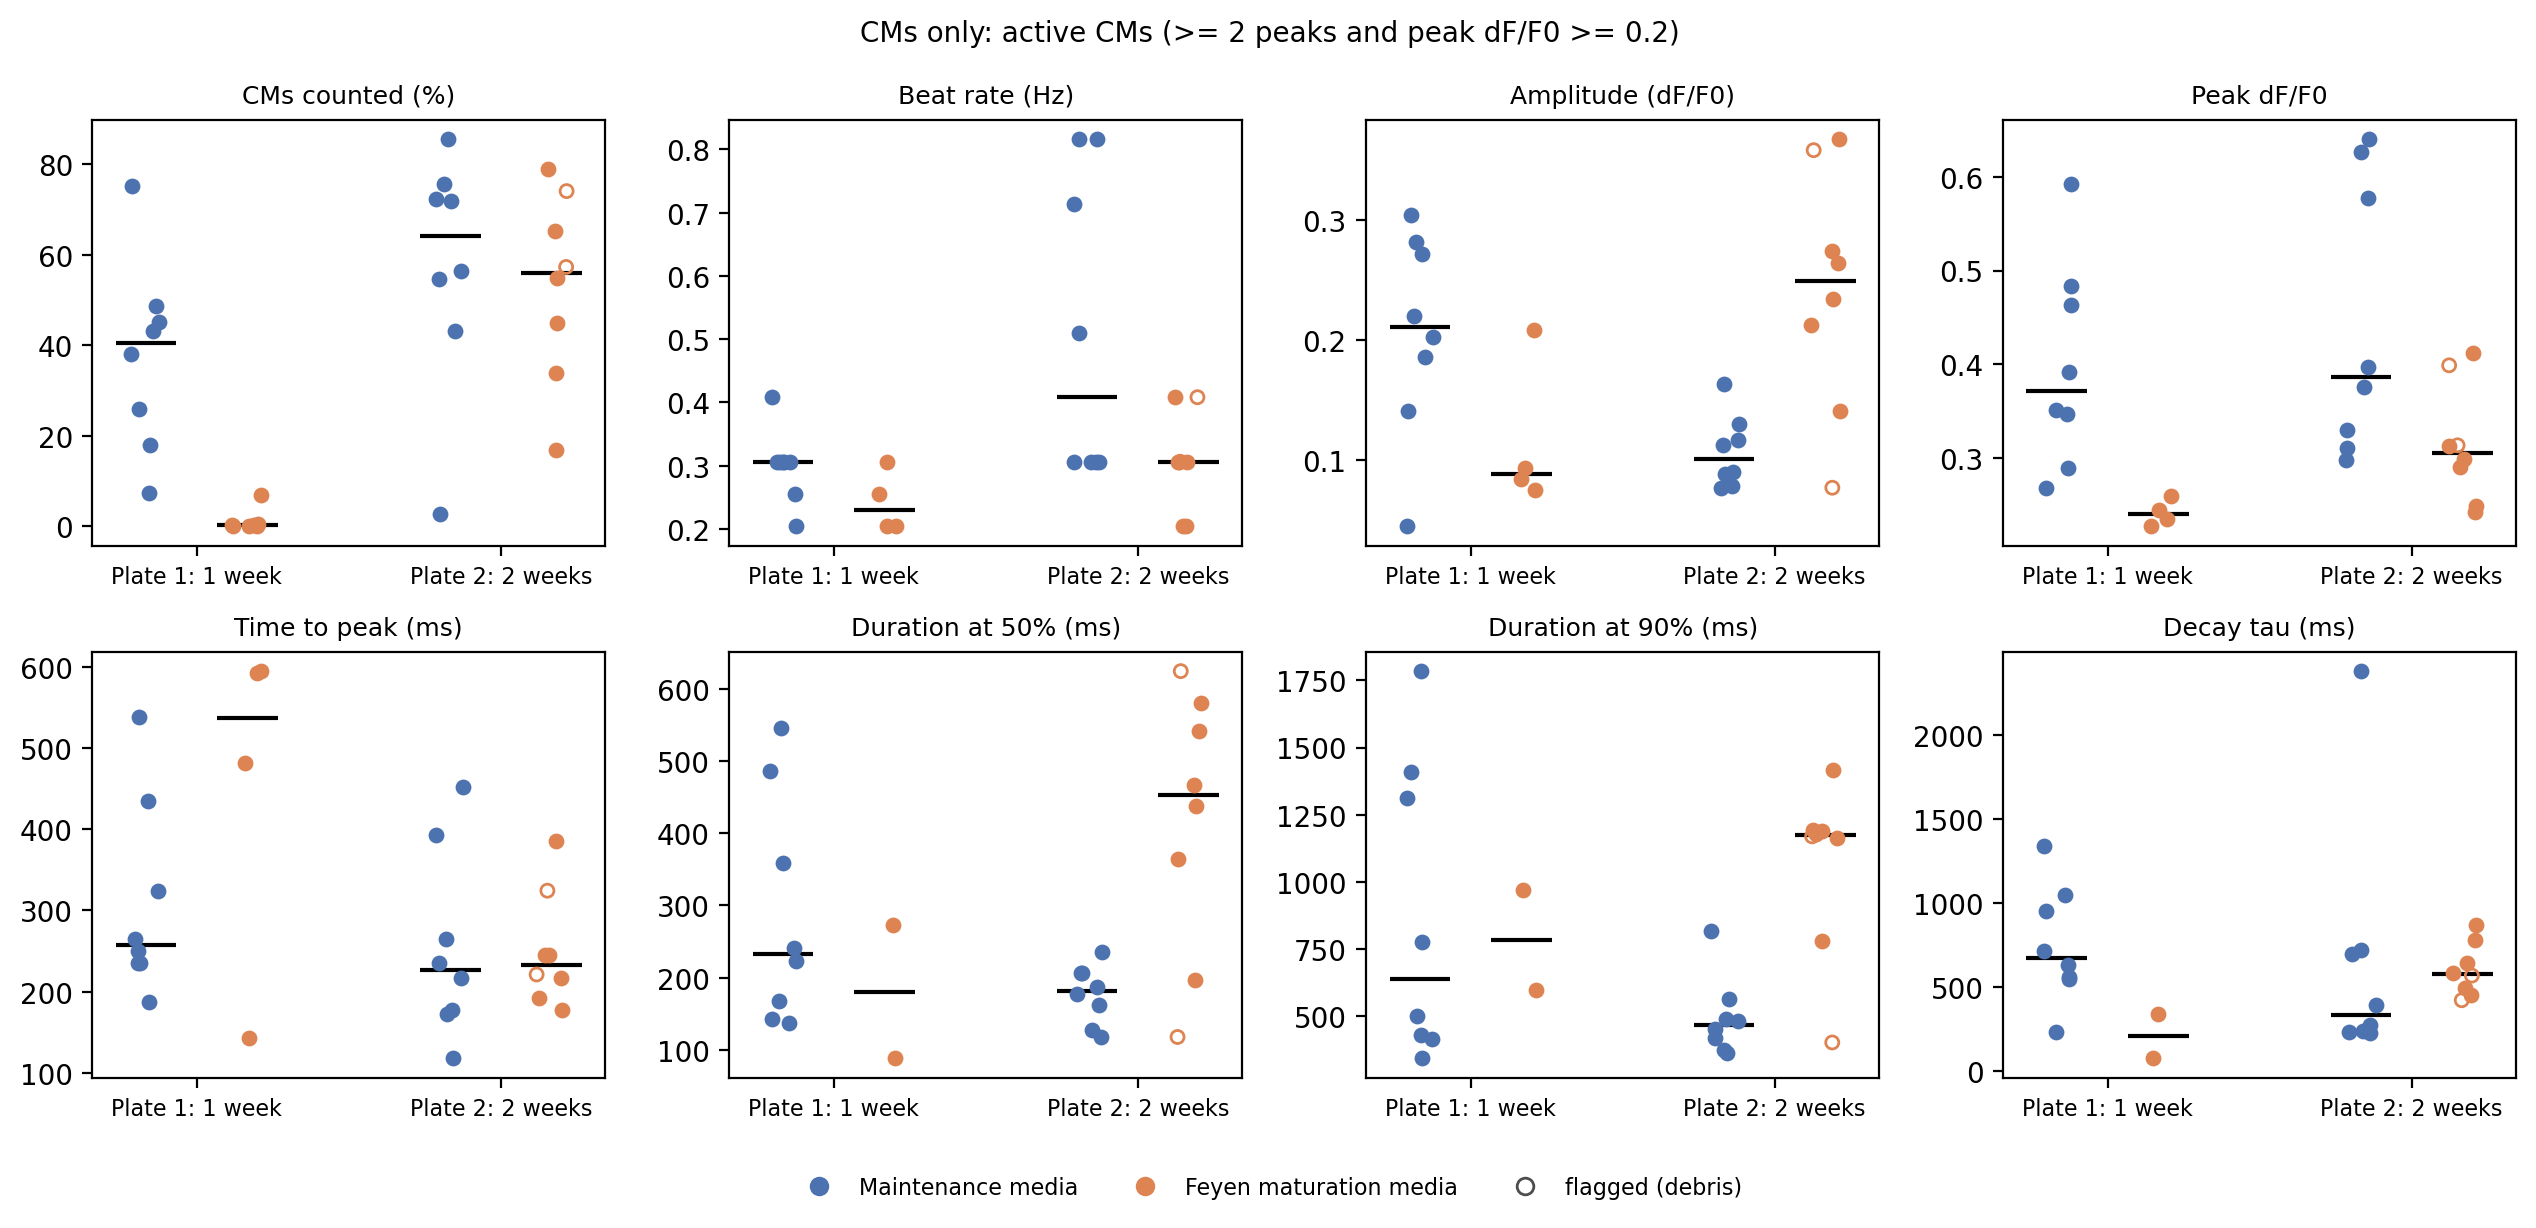

In [16]:
# Version 2: active CMs only (placeholder threshold)
summary_active = summarize_wells(features, min_peak_dff=MIN_PEAK_DFF)
summary_active.to_csv(CALCIUM_DIR / f"well_summary_{PREFIX}active-peak{MIN_PEAK_DFF}.csv", index=False)
well_metrics_active = plot_well_metrics(summary_active,
                                        title=f"CMs only: active CMs (>= 2 peaks and peak dF/F0 >= {MIN_PEAK_DFF})",
                                        export_name=f"well-metrics_active-peak{MIN_PEAK_DFF}")

In [17]:
# Per-well table (beating CMs)
summary_beating.round(3)

,Plate,Well,Condition,n_cm,n_active,pct_beating,flagged,beat_rate,amplitude,peak_dff,time_to_peak,duration_50,duration_90,tau_decay
0,plate1,B02,Maintenance media,723,484,66.943,,0.306,0.047,0.078,0.582,0.118,0.619,0.361
1,plate1,B03,Maintenance media,277,258,93.141,,0.714,0.076,0.095,0.295,0.241,0.801,0.428
2,plate1,B04,Maintenance media,906,826,91.170,,0.306,0.131,0.542,0.342,0.147,0.364,1.013
3,plate1,B05,Maintenance media,433,376,86.836,,0.408,0.086,0.178,0.265,0.219,0.823,0.565
4,plate1,B06,Maintenance media,609,527,86.535,,0.306,0.105,0.275,0.285,0.383,1.165,0.933
5,plate1,B07,Maintenance media,412,326,79.126,,0.306,0.073,0.242,0.297,0.145,0.521,1.385
6,plate1,B08,Maintenance media,710,462,65.070,,0.306,0.053,0.061,0.624,0.118,0.890,1.353
7,plate1,B09,Maintenance media,399,272,68.170,,0.204,0.069,0.276,0.479,0.285,1.248,0.786
8,plate1,C02,Feyen maturation media,319,199,62.382,,0.306,0.044,0.059,0.639,0.108,0.737,1.003
9,plate1,C03,Feyen maturation media,877,626,71.380,,0.306,0.073,0.091,0.501,0.197,0.900,0.424


#### CM-only vs. all-nuclei summaries
Medians of per-well medians, per plate and condition (durations and time to peak in ms). `all nuclei, active` is the notebook-5 table quoted in CLAUDE.md (`well_summary_active-peak0.2.csv`).

In [18]:
COMPARE = ["pct_beating", "beat_rate", "amplitude", "peak_dff", "time_to_peak", "duration_50", "duration_90"]
versions = {
    "all nuclei, active (nb 5)": pd.read_csv(CALCIUM_DIR / f"well_summary_active-peak{MIN_PEAK_DFF}.csv"),
    "all nuclei, beating (nb 5)": pd.read_csv(CALCIUM_DIR / "well_summary_beating.csv"),
    "CMs, beating": summary_beating,
    f"CMs, active": summary_active,
}
comparison = pd.concat({name: group_medians(s, COMPARE) for name, s in versions.items()}, names=["Version"])
comparison = comparison.reorder_levels(["Plate", "Condition", "Version"]).sort_index(
    level=["Plate"], sort_remaining=False)
comparison.to_csv(CALCIUM_DIR / f"well_summary_{PREFIX}comparison.csv")
comparison.round(3)

pct_beating  \
Plate  Condition              Version                                   
plate1 Maintenance media      all nuclei, active (nb 5)         8.566   
       Feyen maturation media all nuclei, active (nb 5)         0.297   
       Maintenance media      all nuclei, beating (nb 5)       62.614   
       Feyen maturation media all nuclei, beating (nb 5)       49.890   
       Maintenance media      CMs, beating                     82.831   
       Feyen maturation media CMs, beating                     55.666   
       Maintenance media      CMs, active                      40.607   
       Feyen maturation media CMs, active                       0.196   
plate2 Maintenance media      all nuclei, active (nb 5)        38.633   
       Feyen maturation media all nuclei, active (nb 5)        35.148   
       Maintenance media      all nuclei, beating (nb 5)       75.463   
       Feyen maturation media all nuclei, beating (nb 5)       73.923   
       Maintenance media      CMs, beating                     88.539   
       Feyen maturation media CMs, beating                     95.266   
       Maintenance media      CMs, active                      64.085   
       Feyen maturation media CMs, active                      56.031   

                                                          beat_rate  \
Plate  Condition              Version                                 
plate1 Maintenance media      all nuclei, active (nb 5)       0.306   
       Feyen maturation media all nuclei, active (nb 5)       0.255   
       Maintenance media      all nuclei, beating (nb 5)      0.306   
       Feyen maturation media all nuclei, beating (nb 5)      0.204   
       Maintenance media      CMs, beating                    0.306   
       Feyen maturation media CMs, beating                    0.306   
       Maintenance media      CMs, active                     0.306   
       Feyen maturation media CMs, active                     0.230   
plate2 Maintenance media      all nuclei, active (nb 5)       0.357   
       Feyen maturation media all nuclei, active (nb 5)       0.306   
       Maintenance media      all nuclei, beating (nb 5)      0.306   
       Feyen maturation media all nuclei, beating (nb 5)      0.306   
       Maintenance media      CMs, beating                    0.306   
       Feyen maturation media CMs, beating                    0.306   
       Maintenance media      CMs, active                     0.408   
       Feyen maturation media CMs, active                     0.306   

                                                          amplitude  peak_dff  \
Plate  Condition              Version                                           
plate1 Maintenance media      all nuclei, active (nb 5)       0.188     0.343   
       Feyen maturation media all nuclei, active (nb 5)       0.099     0.253   
       Maintenance media      all nuclei, beating (nb 5)      0.053     0.074   
       Feyen maturation media all nuclei, beating (nb 5)      0.046     0.056   
       Maintenance media      CMs, beating                    0.075     0.210   
       Feyen maturation media CMs, beating                    0.044     0.059   
       Maintenance media      CMs, active                     0.211     0.372   
       Feyen maturation media CMs, active                     0.089     0.239   
plate2 Maintenance media      all nuclei, active (nb 5)       0.101     0.384   
       Feyen maturation media all nuclei, active (nb 5)       0.249     0.305   
       Maintenance media      all nuclei, beating (nb 5)      0.068     0.232   
       Feyen maturation media all nuclei, beating (nb 5)      0.135     0.186   
       Maintenance media      CMs, beating                    0.081     0.285   
       Feyen maturation media CMs, beating                    0.168     0.245   
       Maintenance media      CMs, active                     0.101     0.387   
       Feyen maturation media CMs, active                     0.249     0.305   

     

#### Interpretation
Exploratory, no statistics (numbers from the tables above, 2026-10-29).

**1. CM content.** Medians of wells: Plate 1 has ~24% CMs among the nuclei in the movie (maintenance 23.5%, Feyen 21.7%), Plate 2 ~60-70% (maintenance 58.2%, Feyen 69.5%). Plate 2's two low Feyen wells are C04 (43.5%, the sparsest well, 1402 nuclei in the movie) and C05 (36.7%, debris). **Plate 1 Feyen has as many CMs as Plate 1 maintenance**, so its near-silence is not from a loss of CMs. The CMs are there and do not fire.

**2. Is the beat criterion still too loose? Yes.** ">= 2 peaks at 5x noise" passes 47-58% of non-CM nuclei, whose peak dF/F0 sits at ~0.04-0.07: that is noise. Among CMs, the peak dF/F0 distribution is itself bimodal, with a silent mode at ~0.05 (it overlaps the non-CMs) and an active mode at ~0.2-0.5, and many silent CMs also pass ">= 2 peaks". For example, Plate 1 Feyen CMs: 58.6% "beating", 1.5% active. So a peak dF/F0 floor is still needed after the CM filter, not just as a stand-in for it. 0.2 sits on the low side of the active mode. On Plate 2 the valley between the CM modes is nearer 0.1-0.15, so 0.2 drops some genuinely active low-amplitude CMs. A lower, data-driven cut is the next thing to try. It is left at 0.2 here so the comparison with notebook 5 is like for like.

**3. With the 0.2 floor, the CM filter barely moves the kinetics.** 97-98% of notebook 5's "active" nuclei on Plate 2 (93% on Plate 1 maintenance) are already cTnT+, so the 0.2 threshold was working as a de facto CM filter. On Plate 2, the CM-active medians of beat rate, amplitude, peak, time to peak, and durations are the same as notebook 5's (amplitude 0.10 vs. 0.25, D50 182 vs. 452 ms, D90 467 vs. 1175 ms, maintenance vs. Feyen). The Feyen result at 2 weeks (larger and longer transients) therefore holds in CMs only.

**4. The CM filter changes the % active a lot, because the denominator is now CMs.** Plate 1 maintenance goes from 8.6% to 40.6% of CMs, Plate 2 maintenance from 38.6% to 64.1%, and Plate 2 Feyen from 35.1% to 56.0%. **Plate 1 Feyen stays silent: 0.2% of CMs are active (median 1 active CM per well, vs. 169 in maintenance).** Its kinetics still rest on almost no cells, so they are still not interpretable.

**5. Without the 0.2 floor ("CMs, beating")**, Plate 2 Feyen CMs "beat" more often than maintenance CMs (95% vs. 89%). However, the medians mix silent and active CMs, so amplitudes and peaks are pulled toward noise, and Plate 1 Feyen looks like a 56% "beating" population with 0.06 peak dF/F0. Do not use this version for biology.

Caveats still apply: beat rate is quantised and confounds amplitude and duration (Plate 2 maintenance B04/B05/B07 beat at ~0.7-0.8 Hz); cross-plate differences mix time in media with imaging session; one well = one replicate.